# Severstal 철강 표면 결함 · 첫 번째 실험

**흐름:** 데이터 확인 → 결함 분포 → RLE 마스크 시각화 → 결함 크기 → 이미지 분할 → 간단한 판별 모델 → 오류 분석 → 축소 크기·OpenCV 전처리의 속도와 성능 비교 → YOLO·U-Net 위치 예측 → 상위 2개 박스 → YOLO·U-Net 위치 예측 → 위치 박스 표시

이 노트북은 `kaggle/data`에 내려받은 **공식 대회 데이터**를 사용합니다. 목표는 먼저 이미지 한 장에 결함이 있는지 판별하는 기준선을 만드는 것입니다. `train.csv`는 **결함이 있는 이미지의 행만** 포함하므로, `train_images`에는 있지만 CSV에 없는 이미지를 정상으로 취급합니다. `test_images`에는 정답이 없어서 성능 평가는 `train_images`를 나눈 홀드아웃에서만 합니다.

VS Code에서 Python 커널을 선택하고 위에서부터 실행하세요. 사용 패키지: `numpy`, `pandas`, `pillow`, `matplotlib`, `scikit-learn`, `opencv-python-headless`. 첫 실행은 전체 이미지에서 간단한 특징을 추출하므로 시간이 걸릴 수 있습니다. 이후 실행은 `test1_features.npz`를 재사용합니다.

## 1. 경로와 데이터 확인

노트북 실행 위치가 프로젝트 루트인지 `kaggle` 폴더인지에 관계없이 `kaggle/data`를 찾습니다. 입력 파일 개수와 라벨 대응을 먼저 점검합니다.

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

SEED = 42
COLORS = {"normal": "#64748B", "defect": "#DC6B31", "blue": "#176B87"}
CLASS_COLORS = ["#176B87", "#E79B38", "#A35D91", "#4E9C76"]
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

search_roots = (Path.cwd(), *Path.cwd().parents)
candidate_dirs = [candidate for root in search_roots for candidate in
                  (root, root / "kaggle", root / "new-chat-2" / "kaggle")]
KAGGLE_DIR = next((p for p in candidate_dirs if (p / "data" / "train.csv").is_file()), None)
if KAGGLE_DIR is None:
    raise FileNotFoundError("kaggle/data/train.csv를 찾지 못했습니다. 노트북과 data 폴더 위치를 확인하세요.")
DATA_DIR = KAGGLE_DIR / "data"

labels = pd.read_csv(DATA_DIR / "train.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
train_paths = sorted((DATA_DIR / "train_images").glob("*.jpg"))
test_paths = sorted((DATA_DIR / "test_images").glob("*.jpg"))
required = {"ImageId", "ClassId", "EncodedPixels"}
if not required.issubset(labels.columns) or not train_paths:
    raise ValueError("train.csv 열 또는 train_images 파일이 예상 형식과 다릅니다.")

manifest = pd.DataFrame({"ImageId": [p.name for p in train_paths]})
positive_ids = set(labels["ImageId"])
manifest["has_defect"] = manifest["ImageId"].isin(positive_ids).astype(int)
missing_images = positive_ids - set(manifest["ImageId"])
if missing_images:
    raise FileNotFoundError(f"CSV에만 있는 이미지 {len(missing_images)}개가 있습니다.")
with Image.open(train_paths[0]) as example:
    WIDTH, HEIGHT = example.size

print("데이터 위치:", DATA_DIR)
print(f"학습 이미지 {len(train_paths):,}장 / 정답 없는 대회 시험 이미지 {len(test_paths):,}장")
print(f"CSV 결함 행 {len(labels):,}개 / 이미지 크기 {WIDTH} × {HEIGHT}")
print("결함 이미지:", f"{manifest.has_defect.sum():,}",
      "| 정상 이미지:", f"{(1 - manifest.has_defect).sum():,}")
print("sample_submission의 ClassId=0은 제출 예시용 값이며 시험 정답이 아닙니다.")

데이터 위치: /Users/yoon/Documents/Codex/2026-11-03/new-chat-2/kaggle/data
학습 이미지 12,568장 / 정답 없는 대회 시험 이미지 5,506장
CSV 결함 행 7,095개 / 이미지 크기 1600 × 256
결함 이미지: 6,666 | 정상 이미지: 5,902
sample_submission의 ClassId=0은 제출 예시용 값이며 시험 정답이 아닙니다.


## 2. 라벨 분포

왼쪽은 학습 이미지의 정상/결함 비율, 가운데는 클래스별 **라벨 행 수**, 오른쪽은 한 이미지에 기록된 결함 클래스 수입니다. 한 이미지에 여러 결함이 있을 수 있어 클래스 행 수의 합이 결함 이미지 수보다 큽니다. 클래스 1~4의 물리적 명칭은 이 CSV만으로 확인할 수 없습니다.

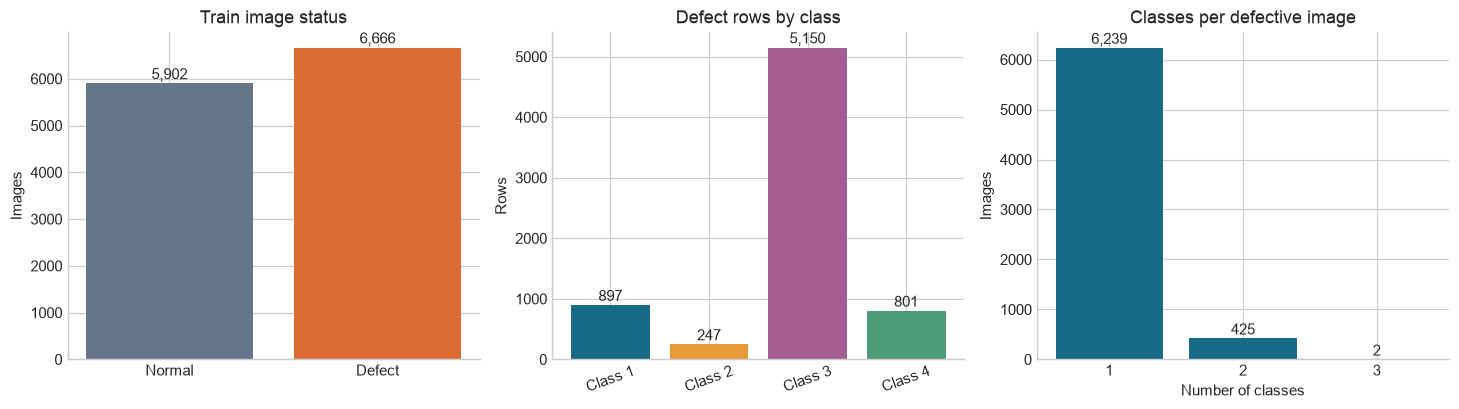

In [40]:
status_counts = manifest["has_defect"].value_counts().reindex([0, 1], fill_value=0)
class_counts = labels["ClassId"].value_counts().reindex([1, 2, 3, 4], fill_value=0)
per_image_classes = labels.groupby("ImageId")["ClassId"].nunique().value_counts().sort_index()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(["Normal", "Defect"], status_counts, color=[COLORS["normal"], COLORS["defect"]])
axes[0].set(title="Train image status", ylabel="Images")
for i, count in enumerate(status_counts):
    axes[0].text(i, count + 90, f"{count:,}", ha="center")

axes[1].bar([f"Class {i}" for i in range(1, 5)], class_counts, color=CLASS_COLORS)
axes[1].set(title="Defect rows by class", ylabel="Rows")
axes[1].tick_params(axis="x", rotation=20)
for i, count in enumerate(class_counts):
    axes[1].text(i, count + 70, f"{count:,}", ha="center")

axes[2].bar(per_image_classes.index.astype(str), per_image_classes.values, color=COLORS["blue"])
axes[2].set(title="Classes per defective image", xlabel="Number of classes", ylabel="Images")
for i, count in enumerate(per_image_classes.values):
    axes[2].text(i, count + 75, f"{count:,}", ha="center")
fig.tight_layout()
plt.show()

## 3. RLE 마스크를 원본 위에 표시

`EncodedPixels`는 마스크의 시작 위치와 길이를 번갈아 저장한 RLE입니다. 시작 위치는 1부터 세며, 픽셀은 **열 우선 순서**로 펼쳐져 있습니다. 아래 그림은 각 클래스에서 결함 면적이 대략 75백분위수인 행을 골라 원본과 마스크를 나란히 보여줍니다. 붉은 부분이 정답 결함 영역입니다.

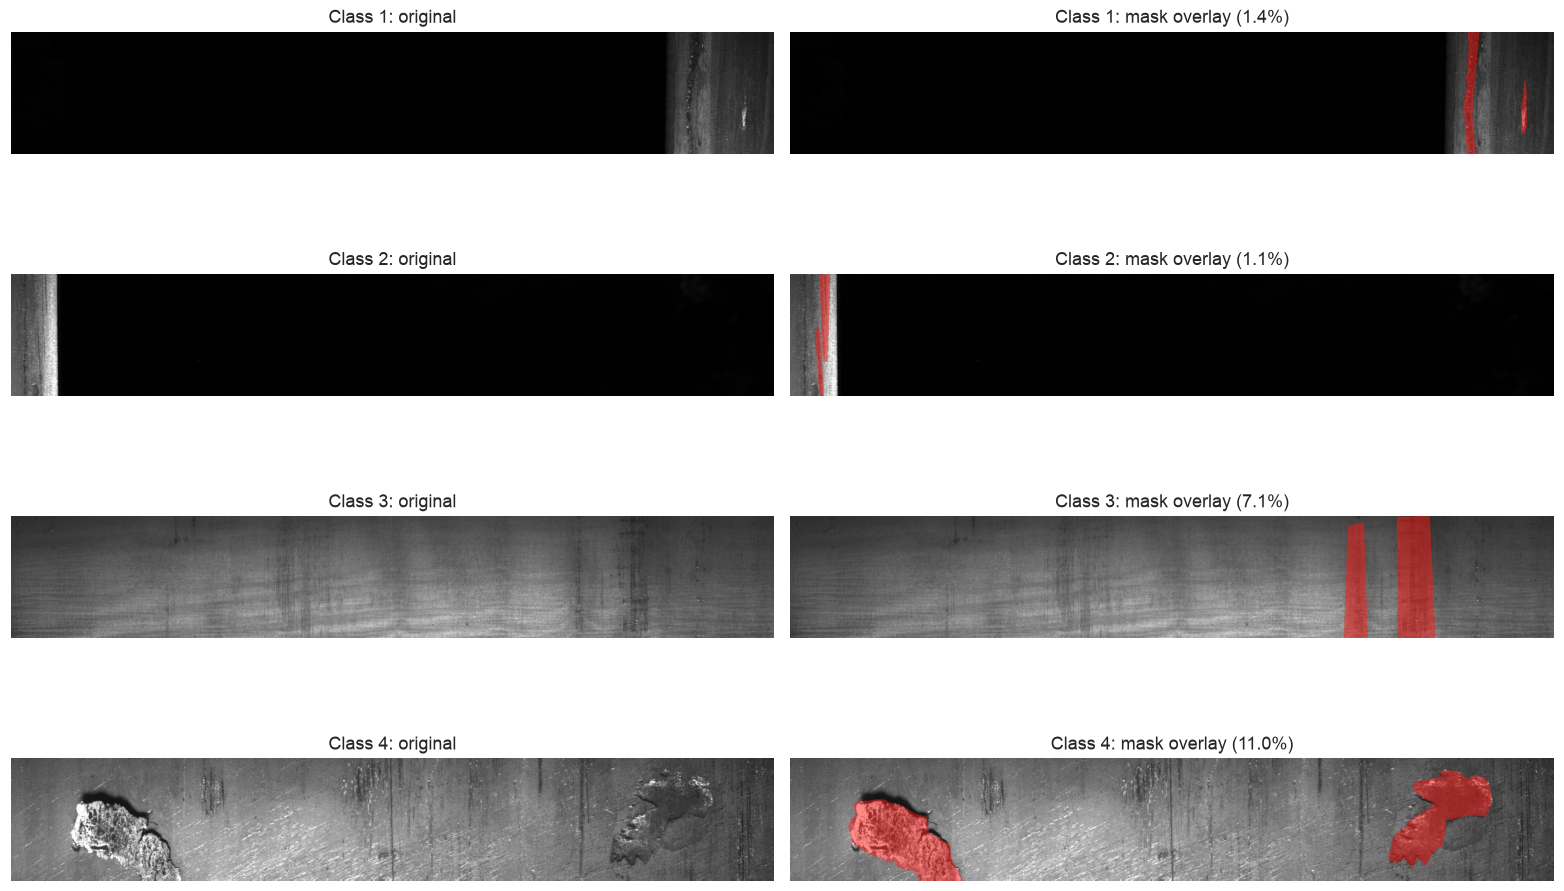

In [41]:
def rle_area(encoded):
    pairs = np.fromstring(encoded, dtype=np.int64, sep=" ")
    if len(pairs) % 2:
        raise ValueError("RLE 숫자 개수가 홀수입니다.")
    return int(pairs[1::2].sum())


def decode_rle(encoded, shape=(HEIGHT, WIDTH)):
    height, width = shape
    pairs = np.fromstring(encoded, dtype=np.int64, sep=" ").reshape(-1, 2)
    flat = np.zeros(height * width, dtype=bool)
    for start, length in pairs:
        first = int(start) - 1
        last = first + int(length)
        if first < 0 or last > len(flat):
            raise ValueError("RLE 범위가 이미지 크기를 벗어났습니다.")
        flat[first:last] = True
    return flat.reshape((width, height)).T


labels["area_px"] = labels["EncodedPixels"].map(rle_area)
labels["coverage_pct"] = 100 * labels["area_px"] / (WIDTH * HEIGHT)
fig, axes = plt.subplots(4, 2, figsize=(15, 10))
for row, class_id in enumerate(range(1, 5)):
    group = labels.loc[labels.ClassId.eq(class_id)]
    target = group.area_px.quantile(0.75)
    record = group.loc[(group.area_px - target).abs().idxmin()]
    with Image.open(DATA_DIR / "train_images" / record.ImageId) as image_file:
        image = np.asarray(image_file.convert("RGB"))
    mask = decode_rle(record.EncodedPixels)
    if mask.sum() != record.area_px:
        raise AssertionError("RLE 면적과 복원 마스크 면적이 다릅니다.")
    overlay = np.zeros((HEIGHT, WIDTH, 4), dtype=np.float32)
    overlay[mask] = (1.0, 0.1, 0.08, 0.5)
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(image)
    axes[row, 1].imshow(overlay)
    axes[row, 0].set_title(f"Class {class_id}: original")
    axes[row, 1].set_title(f"Class {class_id}: mask overlay ({record.coverage_pct:.1f}%)")
    for ax in axes[row]:
        ax.axis("off")
fig.tight_layout()
plt.show()

## 4. 결함 크기 비교

한 CSV 행의 RLE 길이를 합산해 이미지에서 차지하는 면적을 계산했습니다. 아래 비율은 **행별 결함 마스크 면적**입니다. 서로 다른 클래스의 결함이 겹칠 수 있으므로 클래스별 면적을 합쳐 이미지의 고유 결함 면적으로 해석하지 않습니다.

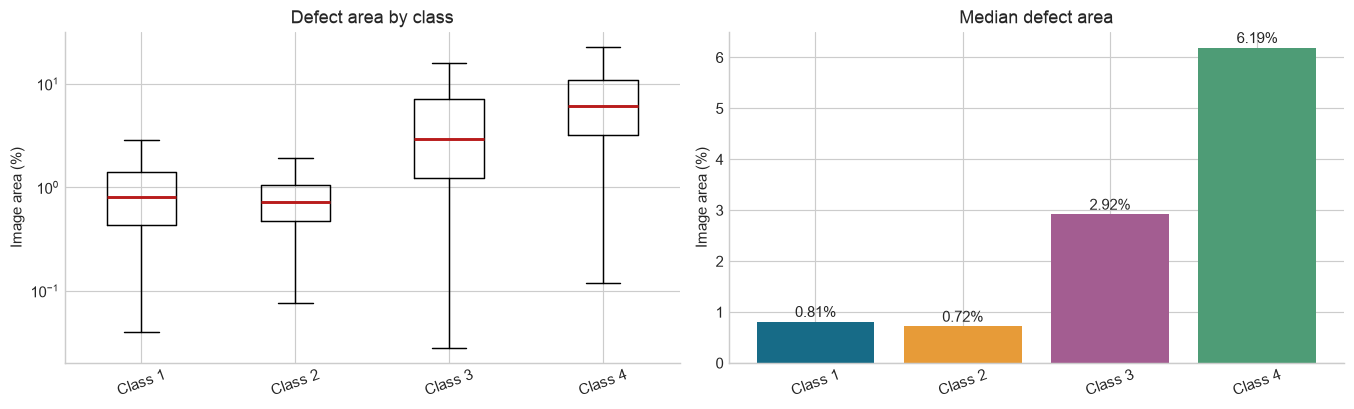

In [42]:
area_by_class = [labels.loc[labels.ClassId.eq(i), "coverage_pct"] for i in range(1, 5)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(area_by_class, tick_labels=[f"Class {i}" for i in range(1, 5)],
                showfliers=False, medianprops={"color": "#B91C1C", "linewidth": 2})
axes[0].set(yscale="log", title="Defect area by class", ylabel="Image area (%)")
axes[0].tick_params(axis="x", rotation=20)
medians = [float(values.median()) for values in area_by_class]
axes[1].bar([f"Class {i}" for i in range(1, 5)], medians, color=CLASS_COLORS)
axes[1].set(title="Median defect area", ylabel="Image area (%)")
axes[1].tick_params(axis="x", rotation=20)
for i, value in enumerate(medians):
    axes[1].text(i, value + max(medians) * 0.015, f"{value:.2f}%", ha="center")
fig.tight_layout()
plt.show()

## 5. 원본 이미지 단위로 학습·검증·시험 분할

하나의 원본 이미지가 여러 세트에 나타나지 않도록 이미지 ID를 먼저 나눕니다. 각 세트의 정상/결함 비율을 비슷하게 맞추며, **학습 60% · 검증 20% · 홀드아웃 시험 20%**를 사용합니다. 검증 세트에서 판정 기준을 고른 뒤 시험 세트는 마지막에 한 번만 평가합니다.

            images  defective  normal  defect_rate_pct
split                                                 
test          2514       1333    1181             53.0
train         7540       3999    3541             53.0
validation    2514       1334    1180             53.1


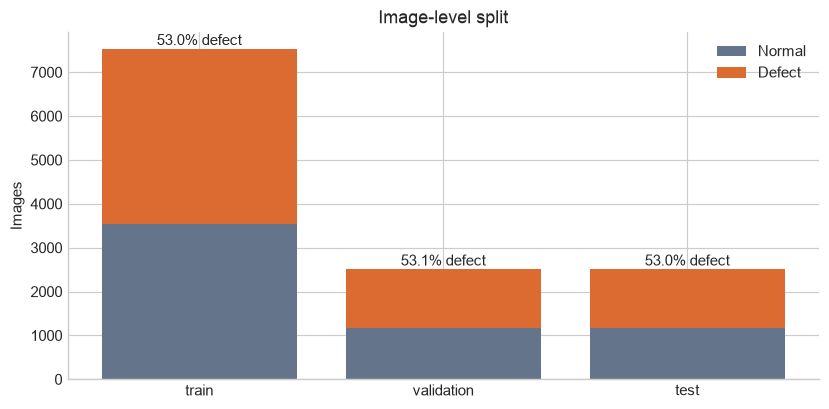

In [43]:
train_idx, other_idx = train_test_split(
    manifest.index.to_numpy(), test_size=0.40,
    stratify=manifest.has_defect, random_state=SEED)
val_idx, test_idx = train_test_split(
    other_idx, test_size=0.50,
    stratify=manifest.loc[other_idx, "has_defect"], random_state=SEED)
manifest["split"] = "train"
manifest.loc[val_idx, "split"] = "validation"
manifest.loc[test_idx, "split"] = "test"
split_table = manifest.groupby("split").has_defect.agg(images="size", defective="sum")
split_table["normal"] = split_table.images - split_table.defective
split_table["defect_rate_pct"] = (100 * split_table.defective / split_table.images).round(1)
print(split_table.to_string())

ordered = split_table.reindex(["train", "validation", "test"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ordered.index, ordered.normal, label="Normal", color=COLORS["normal"])
ax.bar(ordered.index, ordered.defective, bottom=ordered.normal,
       label="Defect", color=COLORS["defect"])
ax.set(title="Image-level split", ylabel="Images")
ax.legend()
for i, row in enumerate(ordered.itertuples()):
    ax.text(i, row.images + 80, f"{row.defect_rate_pct:.1f}% defect", ha="center")
fig.tight_layout()
plt.show()

## 6. 가벼운 이미지 특징 추출

전체 12,568장을 빠르게 훑기 위해 각 이미지를 작은 회색조 이미지로 축소하고 밝기, 명암, 가로·세로 변화량, 다섯 구간의 통계를 추출합니다. 이 기준선은 미세 결함을 놓칠 수 있으며 픽셀 단위 분할 모델은 아닙니다. 재실행 시 동일한 이미지 목록과 특징 이름의 캐시가 있으면 재사용합니다.

In [44]:
FEATURE_NAMES = ["mean", "std", "p05", "p25", "p50", "p75", "p95",
                 "row_mean_std", "col_mean_std", "grad_x_mean", "grad_x_p95",
                 "grad_y_mean", "grad_y_p95", "edge_fraction"]
for segment in range(5):
    FEATURE_NAMES += [f"segment_{segment + 1}_{name}" for name in
                      ("mean", "std", "p10", "p90", "edge_fraction")]


def extract_features(path):
    with Image.open(path) as image:
        image.draft("L", (200, 32))
        gray = np.asarray(image.convert("L").resize((200, 32), Image.Resampling.BILINEAR),
                          dtype=np.float32) / 255.0
    grad_x = np.abs(np.diff(gray, axis=1))
    grad_y = np.abs(np.diff(gray, axis=0))
    q = np.percentile(gray, [5, 25, 50, 75, 95])
    result = [gray.mean(), gray.std(), *q,
              gray.mean(axis=1).std(), gray.mean(axis=0).std(),
              grad_x.mean(), np.percentile(grad_x, 95),
              grad_y.mean(), np.percentile(grad_y, 95),
              (grad_x > 0.10).mean()]
    for segment in np.array_split(gray, 5, axis=1):
        edge = np.abs(np.diff(segment, axis=1))
        result.extend([segment.mean(), segment.std(),
                       np.percentile(segment, 10), np.percentile(segment, 90),
                       (edge > 0.10).mean()])
    return np.asarray(result, dtype=np.float32)


cache_path = KAGGLE_DIR / "test1_features.npz"
X = None
if cache_path.is_file():
    try:
        with np.load(cache_path, allow_pickle=False) as cache:
            if (np.array_equal(cache["image_ids"], manifest.ImageId.to_numpy())
                    and np.array_equal(cache["feature_names"], FEATURE_NAMES)):
                X = cache["features"]
                print("기존 특징 캐시 재사용:", cache_path.name)
    except ValueError:
        print("이전 형식의 특징 캐시를 다시 만듭니다.")
if X is None:
    rows = []
    for i, path in enumerate(train_paths, 1):
        rows.append(extract_features(path))
        if i % 2500 == 0:
            print(f"특징 추출: {i:,}/{len(train_paths):,}")
    X = np.vstack(rows)
    np.savez_compressed(cache_path, image_ids=np.asarray(manifest.ImageId.tolist(), dtype=str),
                        feature_names=np.asarray(FEATURE_NAMES), features=X)
    print("특징 캐시 저장:", cache_path.name)
if X.shape != (len(manifest), len(FEATURE_NAMES)) or not np.isfinite(X).all():
    raise ValueError("특징 행렬 크기 또는 값이 잘못되었습니다.")
print(f"모델 입력: {X.shape[0]:,}장 × {X.shape[1]}개 특징")

기존 특징 캐시 재사용: test1_features.npz
모델 입력: 12,568장 × 39개 특징


## 7. 결함 유무 판별과 검증 기준 선택

랜덤 포레스트를 학습 세트에서만 학습합니다. 검증 세트에서 **결함 재현율 95% 이상**인 기준 중 가장 높은 점수 기준을 골라 불필요한 경보를 줄입니다. 그래프는 정밀도–재현율 곡선과 정상/결함 점수 분포를 보여줍니다. 이 95%는 실험용 목표이며 현장 보증 수치가 아닙니다.

검증 AP 0.952 | ROC AUC 0.950
선택 임계값 0.381 | 검증 재현율 0.951 | 정밀도 0.829


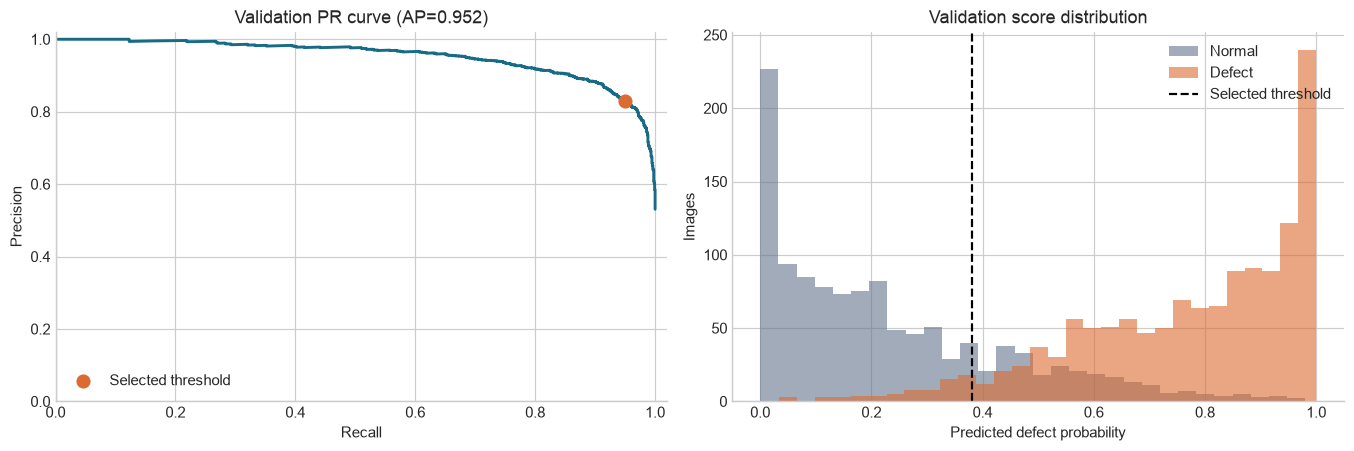

In [45]:
train_mask = manifest.split.eq("train").to_numpy()
val_mask = manifest.split.eq("validation").to_numpy()
test_mask = manifest.split.eq("test").to_numpy()
y = manifest.has_defect.to_numpy()

model = RandomForestClassifier(
    n_estimators=180, min_samples_leaf=5, max_features="sqrt",
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
model.fit(X[train_mask], y[train_mask])
val_score = model.predict_proba(X[val_mask])[:, 1]
val_y = y[val_mask]
precision, recall, thresholds = precision_recall_curve(val_y, val_score)
eligible = np.flatnonzero(recall[:-1] >= 0.95)
threshold = float(thresholds[eligible[-1]])
val_pred = val_score >= threshold
val_ap = average_precision_score(val_y, val_score)
print(f"검증 AP {val_ap:.3f} | ROC AUC {roc_auc_score(val_y, val_score):.3f}")
print(f"선택 임계값 {threshold:.3f} | 검증 재현율 {recall_score(val_y, val_pred):.3f}"
      f" | 정밀도 {precision_score(val_y, val_pred, zero_division=0):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(recall, precision, color=COLORS["blue"], linewidth=2)
axes[0].scatter([recall_score(val_y, val_pred)],
                [precision_score(val_y, val_pred, zero_division=0)],
                color=COLORS["defect"], s=75, zorder=3, label="Selected threshold")
axes[0].set(xlabel="Recall", ylabel="Precision", title=f"Validation PR curve (AP={val_ap:.3f})",
            xlim=(0, 1.02), ylim=(0, 1.02))
axes[0].legend(loc="lower left")
axes[1].hist(val_score[val_y == 0], bins=30, alpha=0.6, label="Normal", color=COLORS["normal"])
axes[1].hist(val_score[val_y == 1], bins=30, alpha=0.6, label="Defect", color=COLORS["defect"])
axes[1].axvline(threshold, color="black", linestyle="--", label="Selected threshold")
axes[1].set(xlabel="Predicted defect probability", ylabel="Images", title="Validation score distribution")
axes[1].legend()
fig.tight_layout()
plt.show()

## 8. 홀드아웃 시험 결과

앞에서 고른 임계값을 고정하고 시험 세트를 평가합니다. 혼동 행렬의 **FN**은 결함을 놓친 이미지, **FP**는 정상인데 경보를 낸 이미지입니다. 클래스별 재현율은 해당 클래스가 기록된 시험 이미지에서 결함 경보가 울린 비율이며, 여러 클래스가 있는 이미지는 각 클래스에 포함됩니다.

시험 이미지 2,514장 | 결함 1,333장
AP 0.950 | ROC AUC 0.949
재현율 0.956 | 정밀도 0.824
TP 1,274 | FN 59 | FP 272 | TN 909


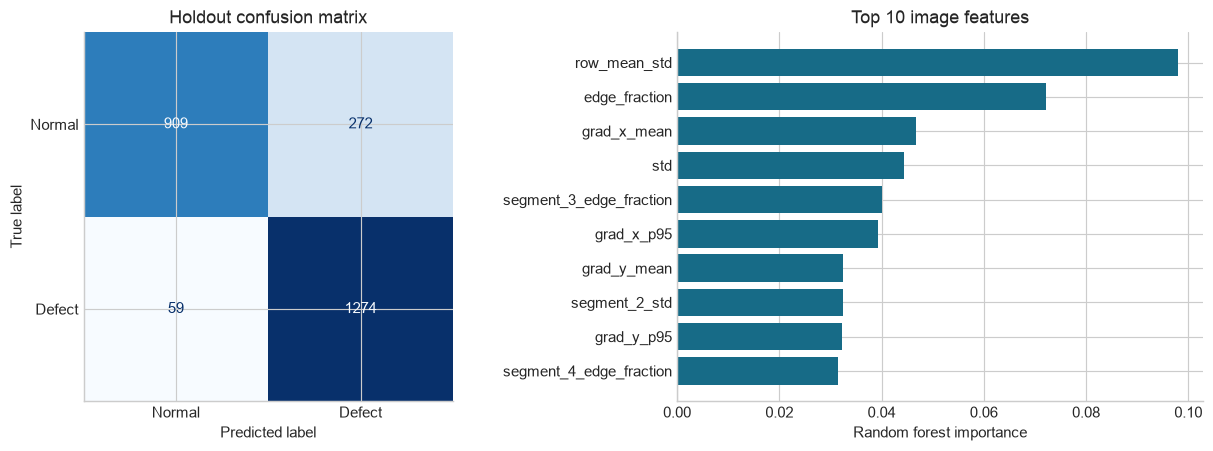


시험 세트 클래스별 경보 결과:
 ClassId  images  detected  recall
       1     182       181   0.995
       2      45        45   1.000
       3    1040       988   0.950
       4     157       148   0.943


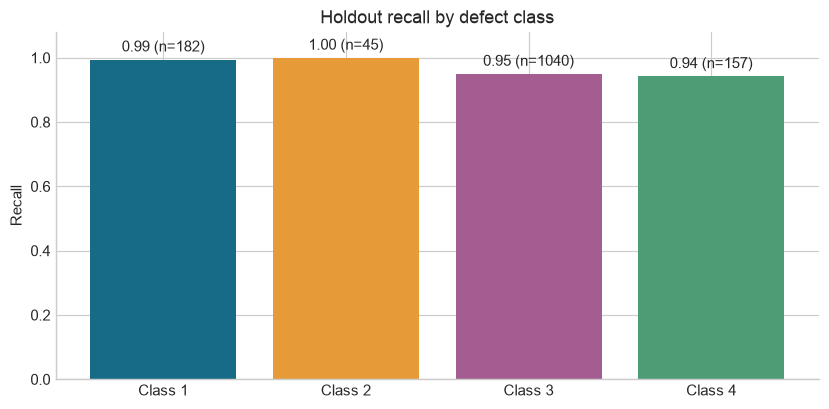

In [46]:
test_score = model.predict_proba(X[test_mask])[:, 1]
test_y = y[test_mask]
test_pred = test_score >= threshold
tn, fp, fn, tp = confusion_matrix(test_y, test_pred, labels=[0, 1]).ravel()
test_ap = average_precision_score(test_y, test_score)
print(f"시험 이미지 {len(test_y):,}장 | 결함 {int(test_y.sum()):,}장")
print(f"AP {test_ap:.3f} | ROC AUC {roc_auc_score(test_y, test_score):.3f}")
print(f"재현율 {recall_score(test_y, test_pred):.3f} | 정밀도 "
      f"{precision_score(test_y, test_pred, zero_division=0):.3f}")
print(f"TP {tp:,} | FN {fn:,} | FP {fp:,} | TN {tn:,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ConfusionMatrixDisplay.from_predictions(test_y, test_pred, labels=[0, 1],
    display_labels=["Normal", "Defect"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Holdout confusion matrix")
importance = pd.Series(model.feature_importances_, index=FEATURE_NAMES).nlargest(10).sort_values()
axes[1].barh(importance.index, importance.values, color=COLORS["blue"])
axes[1].set(xlabel="Random forest importance", title="Top 10 image features")
fig.tight_layout()
plt.show()

test_frame = manifest.loc[test_mask, ["ImageId"]].copy()
test_frame["predicted_defect"] = test_pred
test_ids = test_frame.ImageId.to_numpy()
class_rows = []
for class_id in range(1, 5):
    ids = set(labels.loc[labels.ClassId.eq(class_id), "ImageId"])
    matches = np.isin(test_ids, list(ids))
    support = int(matches.sum())
    detected = int(test_pred[matches].sum())
    class_rows.append((class_id, support, detected, detected / support if support else np.nan))
class_results = pd.DataFrame(class_rows, columns=["ClassId", "images", "detected", "recall"])
print()
print("시험 세트 클래스별 경보 결과:")
print(class_results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([f"Class {i}" for i in class_results.ClassId], class_results.recall, color=CLASS_COLORS)
ax.set(ylim=(0, 1.08), ylabel="Recall", title="Holdout recall by defect class")
for i, row in enumerate(class_results.itertuples()):
    ax.text(i, row.recall + 0.025, f"{row.recall:.2f} (n={row.images})", ha="center")
fig.tight_layout()
plt.show()

## 9. 놓친 결함과 잘못 울린 경보 살펴보기

점수가 가장 낮은 FN 두 장과 점수가 가장 높은 FP 두 장을 보여줍니다. 여기서 보이는 패턴은 원인에 대한 **탐색**일 뿐, 네 장만으로 결함 유형별 성능을 일반화할 수 없습니다.

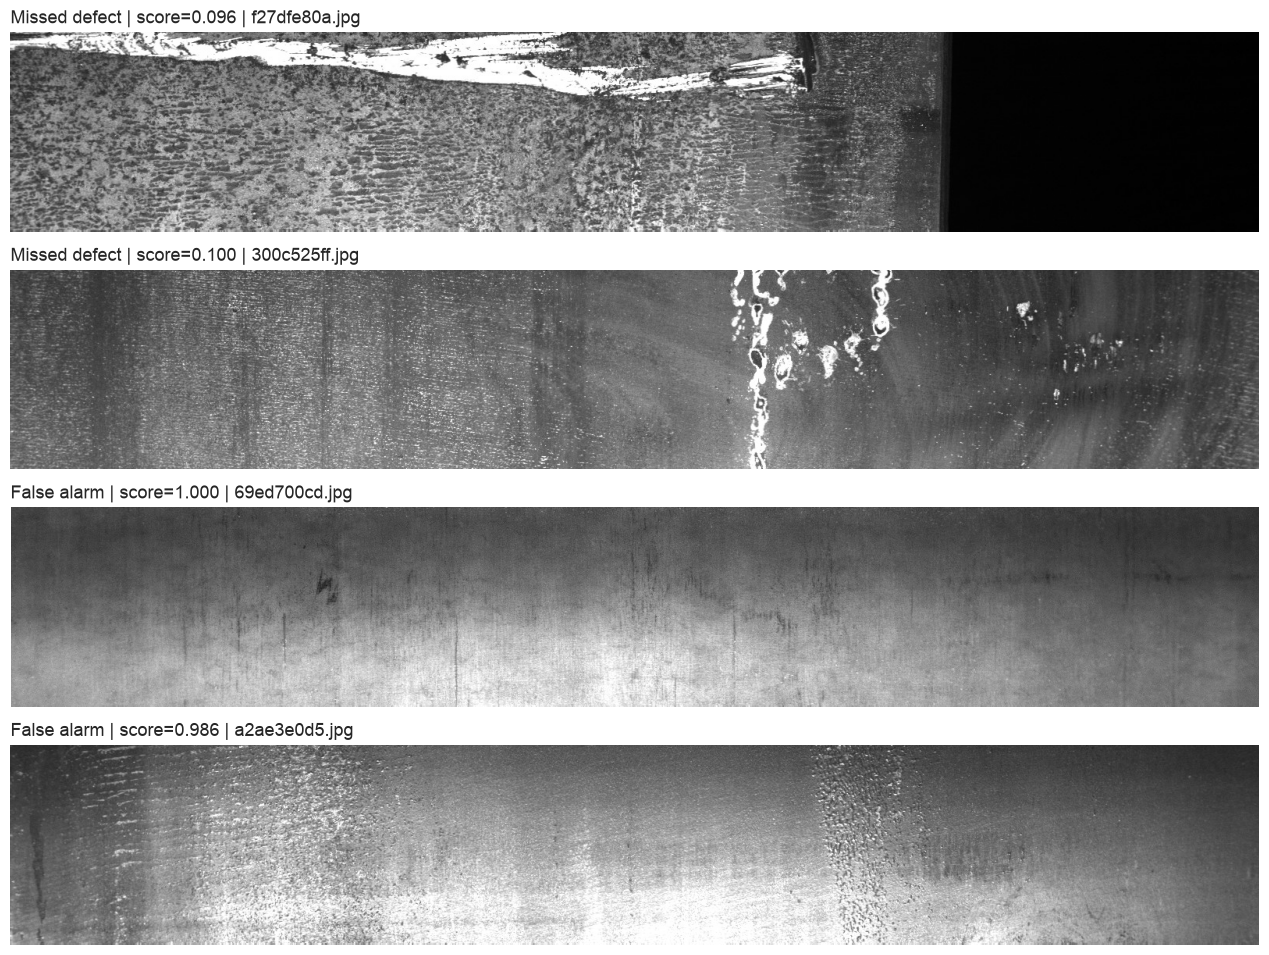

In [47]:
errors = manifest.loc[test_mask, ["ImageId"]].copy().reset_index(drop=True)
errors["truth"] = test_y
errors["score"] = test_score
errors["pred"] = test_pred.astype(int)
false_negative = errors.loc[(errors.truth == 1) & (errors.pred == 0)].nsmallest(2, "score")
false_positive = errors.loc[(errors.truth == 0) & (errors.pred == 1)].nlargest(2, "score")
selected_errors = pd.concat([false_negative.assign(kind="Missed defect"),
                             false_positive.assign(kind="False alarm")], ignore_index=True)
if selected_errors.empty:
    print("이 설정에서 표시할 오류가 없습니다.")
else:
    fig, axes = plt.subplots(len(selected_errors), 1, figsize=(13, 2.3 * len(selected_errors)),
                             squeeze=False)
    for ax, record in zip(axes[:, 0], selected_errors.itertuples()):
        with Image.open(DATA_DIR / "train_images" / record.ImageId) as image_file:
            ax.imshow(image_file.convert("RGB"))
        ax.set_title(f"{record.kind} | score={record.score:.3f} | {record.ImageId}", loc="left")
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 10. 이미지 축소가 실제로 빠른가?

앞의 기준선은 원본 1600×256을 **200×32**로 줄여 특징을 추출했습니다. 원본 1600×256도 같은 특징 추출기와 모델로 직접 측정합니다. 축소가 결함 판별을 빠르게 할 수 있는지 보려면 **읽기·축소·전처리·특징 계산·모델 예측**을 모두 재야 합니다. 학습 시간은 별도로 기록하고, 아래 지연 시간은 홀드아웃 이미지 120장을 한 장씩 처리한 중앙값 기반입니다.

비교 조건은 같은 12,568장, 같은 60/20/20 이미지 분할, 같은 39개 특징과 랜덤 포레스트 설정입니다. 각 방법은 검증 세트에서 재현율 95% 이상인 임계값을 정하고, 그 기준을 시험 세트에 고정 적용합니다. 축소 방식마다 학습 데이터가 달라지므로 **모델을 각각 다시 학습**합니다.

참고 예제는 `AI_02/test01/test12.py`(축소), `test01/test24.py`(Gaussian), `test01/test26.py`(Sobel), `test02_도형/test67.py`(CLAHE), `test02_도형/test51.py`(형태학 연산)입니다. 이 실험의 크기와 커널은 철강 이미지에 맞게 별도로 설정했습니다.

In [48]:
import time
import platform
import cv2
from sklearn.base import clone

cv2.setNumThreads(1)  # 단일 이미지 처리 시간 비교에서 OpenCV 내부 병렬화 고정
print("Python", platform.python_version(), "| OpenCV", cv2.__version__)
print("실행 환경:", platform.platform())


def cv2_preprocess(path, size, method="raw"):
    width, height = size
    flag = (cv2.IMREAD_GRAYSCALE if width > 400 else
            cv2.IMREAD_REDUCED_GRAYSCALE_4 if width > 200 else
            cv2.IMREAD_REDUCED_GRAYSCALE_8)
    gray = cv2.imread(str(path), flag)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape != (height, width):
        gray = cv2.resize(gray, (width, height), interpolation=cv2.INTER_AREA)
    if method == "clahe":
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 2)).apply(gray)
    elif method == "sobel":
        smooth = cv2.GaussianBlur(gray, (3, 3), 0)
        dx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
        dy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)
        magnitude = cv2.magnitude(dx, dy)
        gray = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    elif method == "hats":
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 3))
        bright = cv2.morphologyEx(gray, cv2.MORPH_TOPHAT, kernel)
        dark = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
        gray = cv2.add(bright, dark)
    elif method != "raw":
        raise ValueError(method)
    return gray


def features_from_gray(gray_u8):
    gray = gray_u8.astype(np.float32) / 255.0
    grad_x = np.abs(np.diff(gray, axis=1))
    grad_y = np.abs(np.diff(gray, axis=0))
    q = np.percentile(gray, [5, 25, 50, 75, 95])
    result = [gray.mean(), gray.std(), *q,
              gray.mean(axis=1).std(), gray.mean(axis=0).std(),
              grad_x.mean(), np.percentile(grad_x, 95),
              grad_y.mean(), np.percentile(grad_y, 95),
              (grad_x > 0.10).mean()]
    for segment in np.array_split(gray, 5, axis=1):
        edge = np.abs(np.diff(segment, axis=1))
        result.extend([segment.mean(), segment.std(),
                       np.percentile(segment, 10), np.percentile(segment, 90),
                       (edge > 0.10).mean()])
    return np.asarray(result, dtype=np.float32)


def cv2_features(path, size, method="raw"):
    return features_from_gray(cv2_preprocess(path, size, method))


CONFIGS = [
    {"key": "pillow200", "name": "Pillow 200×32", "size": (200, 32), "method": "pillow"},
    {"key": "cv100raw", "name": "OpenCV 100×16", "size": (100, 16), "method": "raw"},
    {"key": "cv200raw", "name": "OpenCV 200×32", "size": (200, 32), "method": "raw"},
    {"key": "cv400raw", "name": "OpenCV 400×64", "size": (400, 64), "method": "raw"},
    {"key": "cv1600raw", "name": "OpenCV 1600×256 (original)", "size": (1600, 256), "method": "raw"},
    {"key": "cv200clahe", "name": "200×32 + CLAHE", "size": (200, 32), "method": "clahe"},
    {"key": "cv200sobel", "name": "200×32 + Blur/Sobel", "size": (200, 32), "method": "sobel"},
    {"key": "cv200hats", "name": "200×32 + Top/Black-hat", "size": (200, 32), "method": "hats"},
]

Python 3.14.7 | OpenCV 5.0.0
실행 환경: macOS-26.6.2-arm64-arm-64bit-Mach-O


## 11. 같은 이미지에 전처리를 적용하면

첫 그림은 축소 크기에 따라 남는 세부 정보가 달라지는 모습입니다. 두 번째 그림은 **같은 200×32 이미지**에 대비 보정, 블러 후 에지 추출, 밝고 어두운 작은 구조 강조를 적용한 결과입니다. 이 그림은 변환이 어떻게 보이는지 보여줄 뿐, 성능 우열은 다음 절의 실험으로 판단합니다.

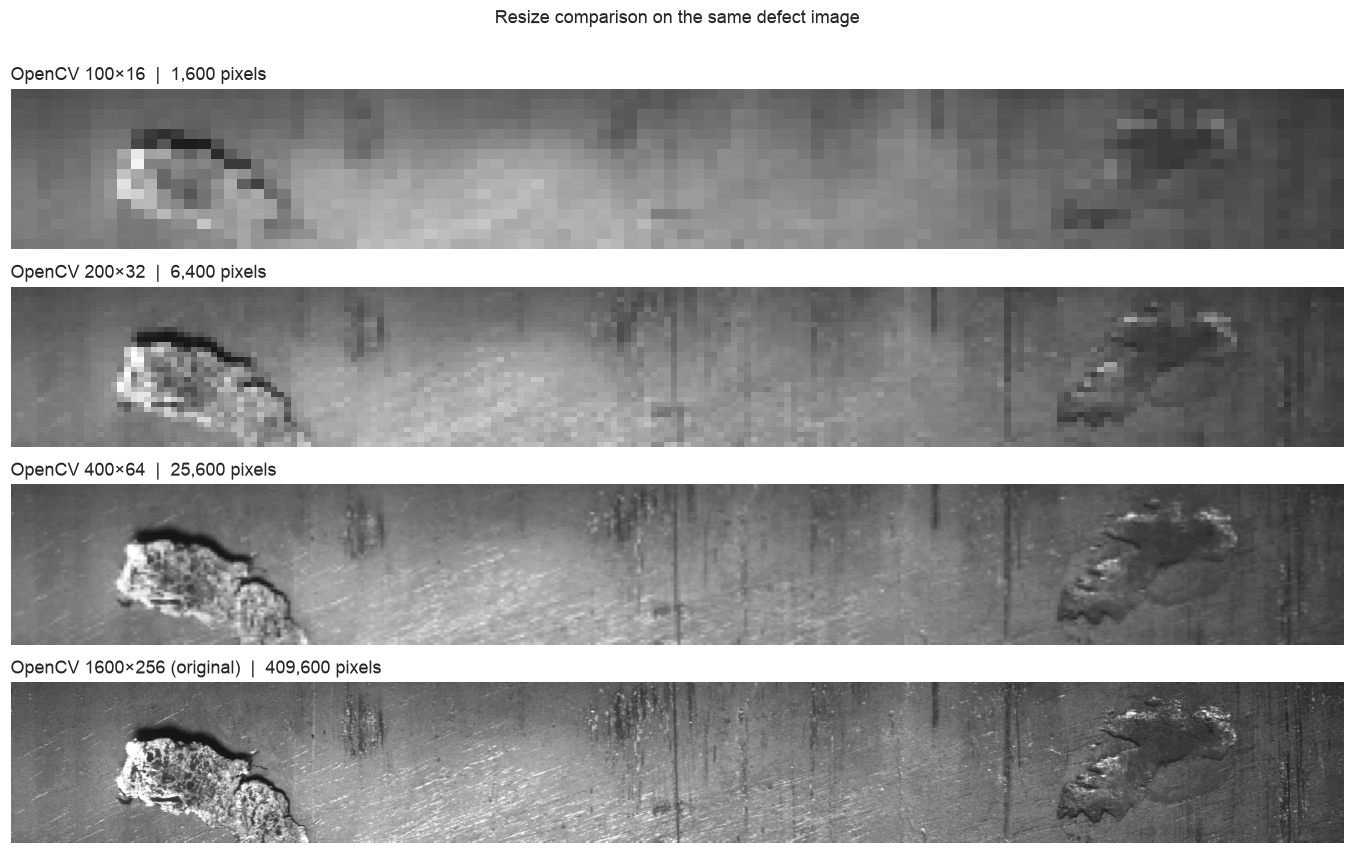

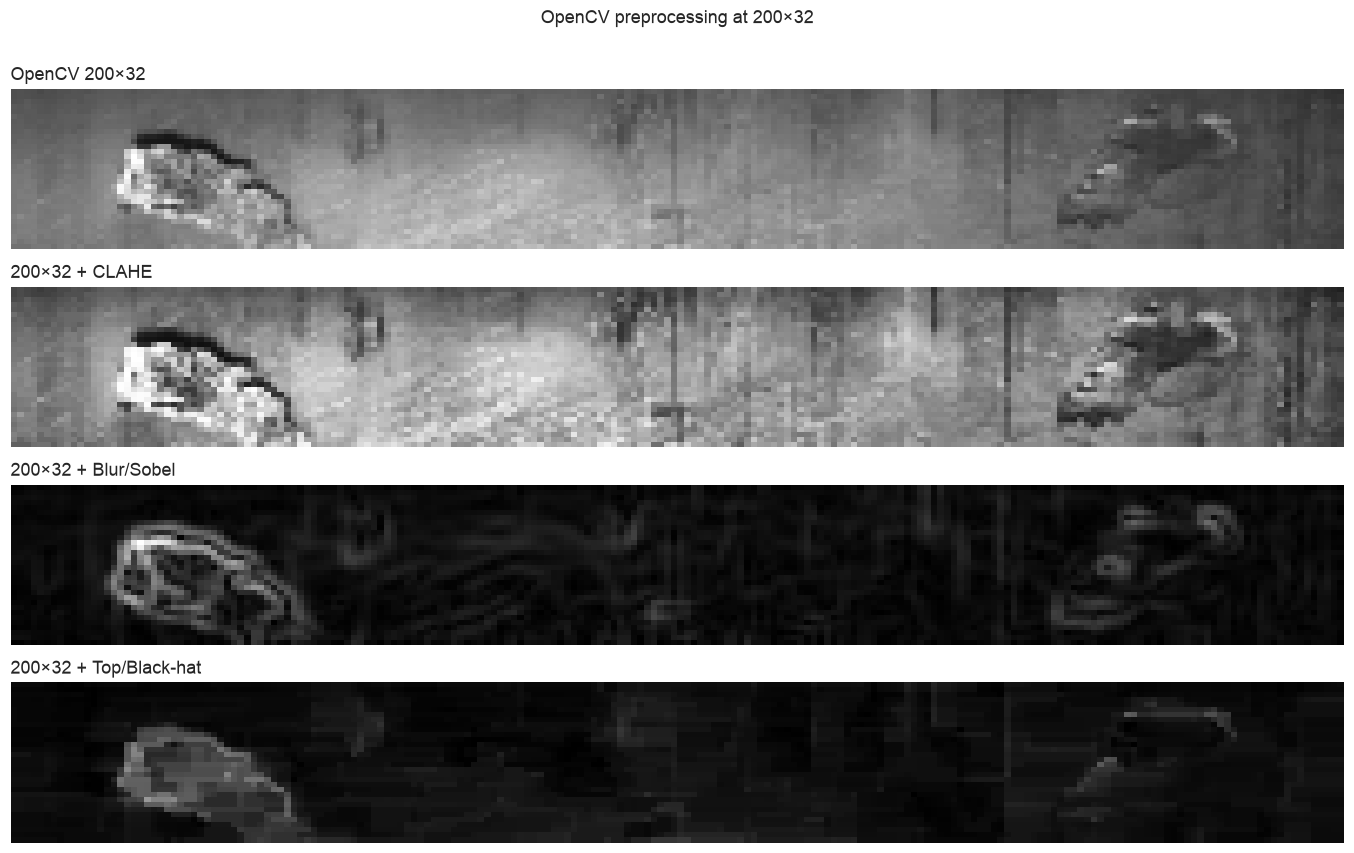

In [49]:
class_four = labels.loc[labels.ClassId.eq(4)]
target_area = class_four.area_px.quantile(0.75)
visual_id = class_four.loc[(class_four.area_px - target_area).abs().idxmin(), "ImageId"]
visual_path = DATA_DIR / "train_images" / visual_id

fig, axes = plt.subplots(4, 1, figsize=(13, 8))
for ax, cfg in zip(axes, CONFIGS[1:5]):
    transformed = cv2_preprocess(visual_path, cfg["size"], "raw")
    ax.imshow(transformed, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(f"{cfg['name']}  |  {transformed.shape[1] * transformed.shape[0]:,} pixels", loc="left")
    ax.axis("off")
fig.suptitle("Resize comparison on the same defect image", y=1.01)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(13, 8))
for ax, cfg in zip(axes, [CONFIGS[2], *CONFIGS[5:]]):
    transformed = cv2_preprocess(visual_path, cfg["size"], cfg["method"])
    ax.imshow(transformed, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(cfg["name"], loc="left")
    ax.axis("off")
fig.suptitle("OpenCV preprocessing at 200×32", y=1.01)
fig.tight_layout()
plt.show()

## 12. 속도와 판별 결과 비교

특징은 모든 학습 이미지에서 계산하고 변형별로 캐시합니다. 실행 시간은 **워밍업 후 동일한 홀드아웃 이미지 120장**을 일곱 번 순차 처리한 각 회차의 한 장당 평균 시간에서 구한 중앙값입니다. 디스크 캐시와 사용 중인 하드웨어에 영향을 받으므로 절대적인 생산 라인 처리량으로 해석하지 않습니다. 모델 학습은 오프라인 단계라 한 장당 추론 시간과 따로 표시합니다.

In [50]:
CV_CACHE = KAGGLE_DIR / "test1_cv_cache"
CV_CACHE.mkdir(exist_ok=True)
image_ids_for_cache = np.asarray(manifest.ImageId.tolist(), dtype=str)
benchmark_paths = [DATA_DIR / "train_images" / image_id for image_id in
                   manifest.loc[test_mask, "ImageId"].sample(n=120, random_state=SEED)]


def feature_matrix(config):
    if config["method"] == "pillow":
        return X
    cache_file = CV_CACHE / f"{config['key']}.npz"
    if cache_file.exists():
        with np.load(cache_file, allow_pickle=False) as saved:
            if (np.array_equal(saved["image_ids"], image_ids_for_cache)
                    and str(saved["cv2_version"]) == cv2.__version__
                    and saved["features"].shape == X.shape):
                print("특징 캐시 재사용:", config["name"])
                return saved["features"]
    started = time.perf_counter()
    matrix = np.vstack([cv2_features(path, config["size"], config["method"])
                        for path in train_paths])
    elapsed = time.perf_counter() - started
    if matrix.shape != X.shape or not np.isfinite(matrix).all():
        raise ValueError(f"특징 오류: {config['name']}")
    np.savez_compressed(cache_file, image_ids=image_ids_for_cache,
                        cv2_version=np.asarray(cv2.__version__), features=matrix)
    print(f"특징 계산: {config['name']} | 전체 {len(train_paths):,}장 | {elapsed:.1f}초")
    return matrix


def one_image_features(path, config):
    if config["method"] == "pillow":
        return extract_features(path)
    return cv2_features(path, config["size"], config["method"])


def benchmark_one_image(config, classifier):
    for path in benchmark_paths[:8]:
        classifier.predict_proba(one_image_features(path, config)[None, :])
    timings = []
    for _ in range(7):
        prep_seconds = pred_seconds = 0.0
        for path in benchmark_paths:
            t0 = time.perf_counter()
            feature = one_image_features(path, config)
            t1 = time.perf_counter()
            classifier.predict_proba(feature[None, :])
            t2 = time.perf_counter()
            prep_seconds += t1 - t0
            pred_seconds += t2 - t1
        timings.append((prep_seconds / len(benchmark_paths) * 1000,
                        pred_seconds / len(benchmark_paths) * 1000))
    timings = np.asarray(timings)
    prep_ms, pred_ms = np.median(timings, axis=0)
    q25, q75 = np.percentile(timings.sum(axis=1), [25, 75])
    return float(prep_ms), float(pred_ms), float(q25), float(q75)


comparison_rows = []
for config in CONFIGS:
    features = feature_matrix(config)
    classifier = clone(model)
    started = time.perf_counter()
    classifier.fit(features[train_mask], y[train_mask])
    fit_s = time.perf_counter() - started
    classifier.n_jobs = 1  # 한 장씩 순차 판별하는 상황의 예측 시간
    val_prob = classifier.predict_proba(features[val_mask])[:, 1]
    test_prob = classifier.predict_proba(features[test_mask])[:, 1]
    prec_curve, rec_curve, candidate_thresholds = precision_recall_curve(val_y, val_prob)
    feasible = np.flatnonzero(rec_curve[:-1] >= 0.95)
    cutoff = float(candidate_thresholds[feasible[-1]])
    val_hat = val_prob >= cutoff
    test_hat = test_prob >= cutoff
    prep_ms, pred_ms, q25_ms, q75_ms = benchmark_one_image(config, classifier)
    row = {
        "method": config["name"], "size": f"{config['size'][0]}×{config['size'][1]}",
        "val_ap": average_precision_score(val_y, val_prob),
        "val_recall": recall_score(val_y, val_hat),
        "val_fp": int(((val_y == 0) & val_hat).sum()),
        "test_ap": average_precision_score(test_y, test_prob),
        "test_recall": recall_score(test_y, test_hat),
        "test_precision": precision_score(test_y, test_hat, zero_division=0),
        "test_fn": int(((test_y == 1) & ~test_hat).sum()),
        "test_fp": int(((test_y == 0) & test_hat).sum()),
        "preprocess_ms": prep_ms, "predict_ms": pred_ms,
        "total_ms": prep_ms + pred_ms, "latency_q25_ms": q25_ms,
        "latency_q75_ms": q75_ms, "fit_s": fit_s, "threshold": cutoff,
    }
    comparison_rows.append(row)
    print(f"{config['name']}: {row['total_ms']:.2f} ms/image | "
          f"validation AP {row['val_ap']:.3f} | holdout FN {row['test_fn']}")

comparison = pd.DataFrame(comparison_rows)
baseline_ms = comparison.loc[comparison.method.eq("Pillow 200×32"), "total_ms"].iloc[0]
comparison["speed_vs_pillow"] = baseline_ms / comparison.total_ms
comparison["latency_iqr_ms"] = comparison.latency_q75_ms - comparison.latency_q25_ms
print()
print("판별 성능 (같은 분할, 검증에서 임계값 선택)")
print(comparison[["method", "val_ap", "val_recall", "val_fp", "test_recall",
                  "test_precision", "test_fn", "test_fp"]].round(3).to_string(index=False))
print()
print("속도 (이미지 한 장, 읽기·전처리·특징·예측 포함)")
print(comparison[["method", "preprocess_ms", "predict_ms", "total_ms",
                  "latency_iqr_ms", "speed_vs_pillow", "fit_s"]].round(3).to_string(index=False))
print()
print("참고: 200×32 두 구현의 작은 속도 차이는 실행 상태에 따라 뒤바뀔 수 있습니다.")
print("예측 시간 자체가 전체 지연 시간의 큰 부분이므로, 크기 축소의 효과는 제한적입니다.")


Pillow 200×32: 6.92 ms/image | validation AP 0.952 | holdout FN 59
특징 캐시 재사용: OpenCV 100×16
OpenCV 100×16: 6.64 ms/image | validation AP 0.948 | holdout FN 72
특징 캐시 재사용: OpenCV 200×32
OpenCV 200×32: 6.66 ms/image | validation AP 0.952 | holdout FN 59
특징 캐시 재사용: OpenCV 400×64
OpenCV 400×64: 7.55 ms/image | validation AP 0.955 | holdout FN 81
특징 캐시 재사용: OpenCV 1600×256 (original)
OpenCV 1600×256 (original): 21.10 ms/image | validation AP 0.953 | holdout FN 60
특징 캐시 재사용: 200×32 + CLAHE
200×32 + CLAHE: 6.58 ms/image | validation AP 0.954 | holdout FN 60
특징 캐시 재사용: 200×32 + Blur/Sobel
200×32 + Blur/Sobel: 6.63 ms/image | validation AP 0.923 | holdout FN 69
특징 캐시 재사용: 200×32 + Top/Black-hat
200×32 + Top/Black-hat: 6.74 ms/image | validation AP 0.929 | holdout FN 54

판별 성능 (같은 분할, 검증에서 임계값 선택)
                    method  val_ap  val_recall  val_fp  test_recall  test_precision  test_fn  test_fp
             Pillow 200×32   0.952       0.951     262        0.956           0.824       59      27

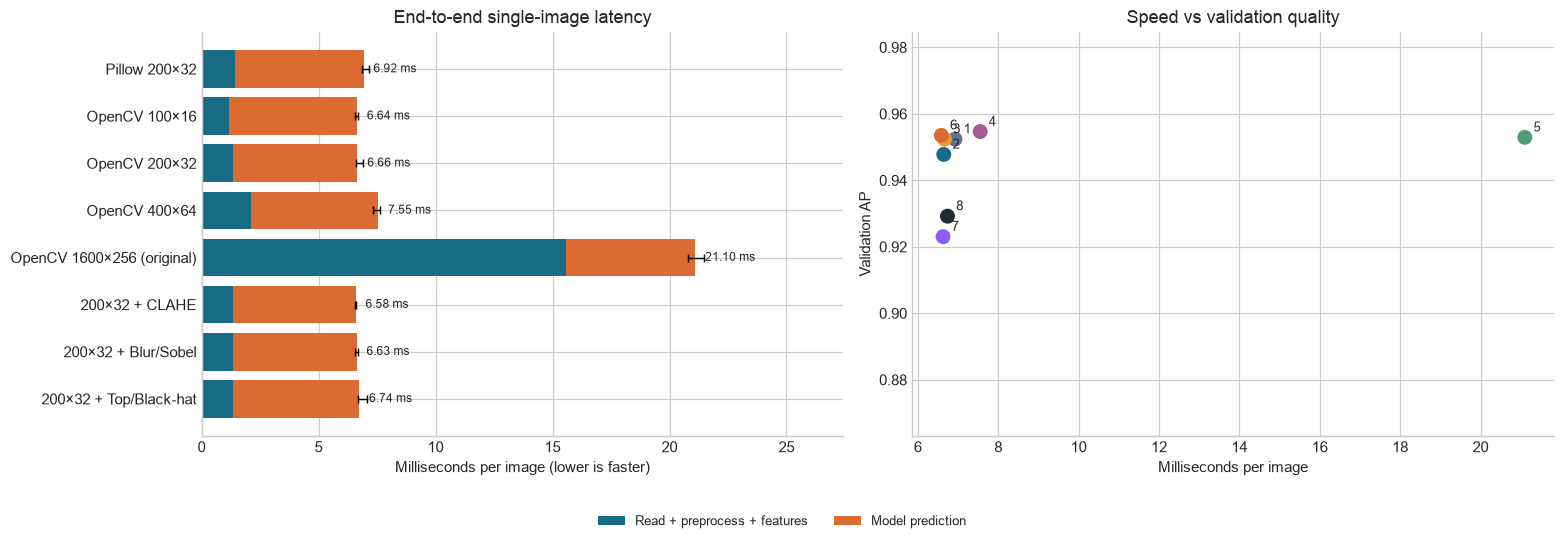

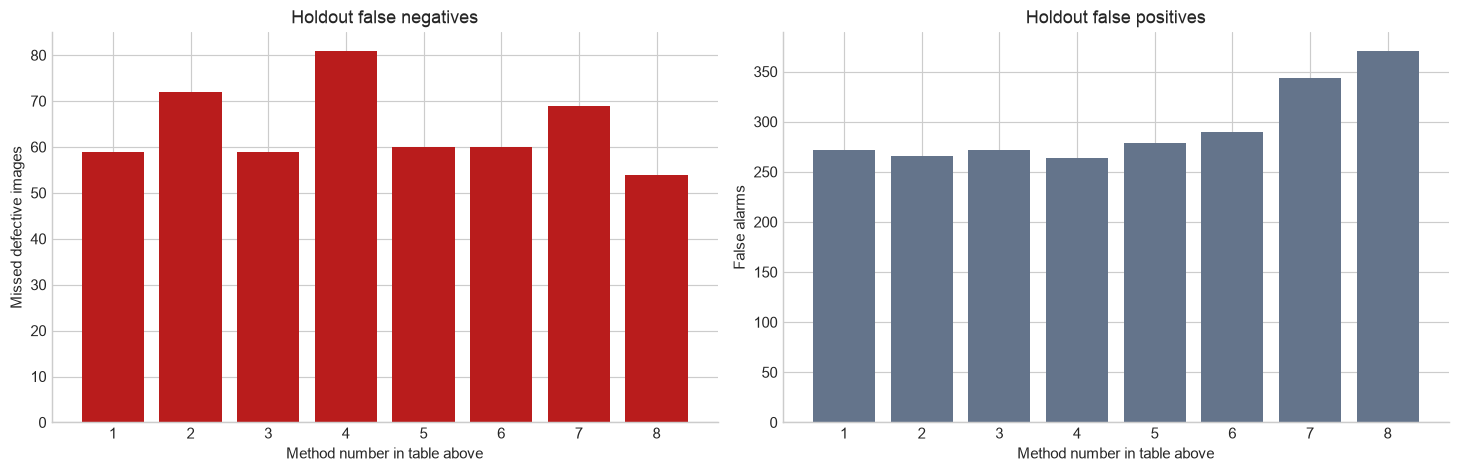

In [51]:
names = comparison.method.tolist()
positions = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].barh(positions, comparison.preprocess_ms, color=COLORS["blue"], label="Read + preprocess + features")
axes[0].barh(positions, comparison.predict_ms, left=comparison.preprocess_ms,
             color=COLORS["defect"], label="Model prediction")
axes[0].set_yticks(positions, names)
axes[0].invert_yaxis()
axes[0].set(xlabel="Milliseconds per image (lower is faster)", title="End-to-end single-image latency")
for i, milliseconds in enumerate(comparison.total_ms):
    axes[0].text(milliseconds + max(comparison.total_ms) * 0.02, i,
                 f"{milliseconds:.2f} ms", va="center", fontsize=8)
axes[0].set_xlim(0, max(comparison.total_ms) * 1.3)
left_error = np.maximum(0, comparison.total_ms - comparison.latency_q25_ms)
right_error = np.maximum(0, comparison.latency_q75_ms - comparison.total_ms)
axes[0].errorbar(comparison.total_ms, positions,
                 xerr=np.vstack([left_error, right_error]), fmt="none",
                 ecolor="black", capsize=3, linewidth=1)

axes[1].scatter(comparison.total_ms, comparison.val_ap, s=85,
                c=[COLORS["normal"], *CLASS_COLORS, COLORS["defect"], "#8B5CF6", "#1F2937"][:len(comparison)])
for i, row in enumerate(comparison.itertuples()):
    axes[1].annotate(str(i + 1), (row.total_ms, row.val_ap),
                     xytext=(6, 4), textcoords="offset points", fontsize=9)
axes[1].set(xlabel="Milliseconds per image", ylabel="Validation AP",
            title="Speed vs validation quality")
axes[1].set_ylim(max(0, comparison.val_ap.min() - 0.06), min(1.02, comparison.val_ap.max() + 0.03))
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, 0.0),
           ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(positions, comparison.test_fn, color="#B91C1C")
axes[0].set(ylabel="Missed defective images", title="Holdout false negatives")
axes[1].bar(positions, comparison.test_fp, color=COLORS["normal"])
axes[1].set(ylabel="False alarms", title="Holdout false positives")
for ax in axes:
    ax.set_xticks(positions, [str(i) for i in positions + 1])
    ax.set_xlabel("Method number in table above")
fig.tight_layout()
plt.show()

## 13. 원본 1600×256과 200×32 직접 비교

두 크기에 **같은 39개 통계 특징, 같은 이미지 분할, 같은 랜덤 포레스트 설정**을 적용합니다. 각 모델의 판정 기준은 검증 세트에서 재현율 95%를 만족하도록 따로 정하고, 같은 홀드아웃 이미지에서 비교합니다. 따라서 이 결과는 현재 특징 추출 방식의 축소 효과를 보여주며, 모든 종류의 이미지 모델에 대한 결론은 아닙니다.

전체 누락 수가 같아도 놓친 이미지가 달라질 수 있습니다. 아래에서는 두 모델이 서로 다른 결함을 찾아내는지 확인하고, RLE 면적을 합산한 **결함 크기 근사치**의 사분위별 재현율을 비교합니다. 클래스 간 마스크가 겹칠 수 있어 이 크기는 정확한 합집합 면적은 아닙니다.

특징 캐시 재사용: OpenCV 200×32
특징 캐시 재사용: OpenCV 1600×256 (original)
같은 홀드아웃 이미지의 직접 비교:
         method  missed_defects  false_alarms
  OpenCV 200×32              59           272
OpenCV 1600×256              60           279
축소본만 찾아낸 결함 29장 | 원본만 찾아낸 결함 28장 | 두 방법 모두 놓친 결함 31장
축소본 - 원본 재현율 차이: +0.08%p | 짝지은 부트스트랩 95% 구간 [-0.98, +1.20]%p

결함 클래스별 재현율 (복수 클래스 이미지는 각 클래스에 포함):
 ClassId  images  recall_200  recall_original  difference_pp
       1     182       0.995            0.973          2.198
       2      45       1.000            0.978          2.222
       3    1040       0.950            0.957         -0.673
       4     157       0.943            0.930          1.274

결함 면적 사분위별 재현율:
area_group  images  recall_200  recall_original  difference_pp
  Smallest     334       0.967            0.955          1.198
     Small     333       0.970            0.958          1.201
     Large     333       0.970            0.973         -0.300
   Largest     333       0.916            0.934      

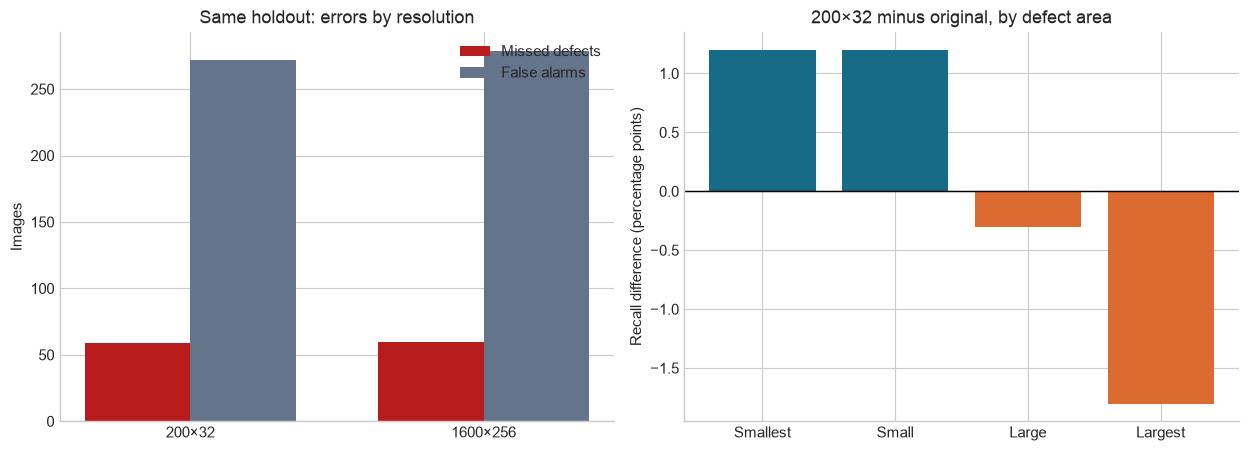

In [52]:
def predict_with_validation_cutoff(config):
    features = feature_matrix(config)
    classifier = clone(model)
    classifier.fit(features[train_mask], y[train_mask])
    validation_score = classifier.predict_proba(features[val_mask])[:, 1]
    _, recall_curve, cutoffs = precision_recall_curve(val_y, validation_score)
    selected_cutoff = float(cutoffs[np.flatnonzero(recall_curve[:-1] >= 0.95)[-1]])
    return classifier.predict_proba(features[test_mask])[:, 1] >= selected_cutoff


small_prediction = predict_with_validation_cutoff(CONFIGS[2])  # OpenCV 200×32
full_prediction = predict_with_validation_cutoff(CONFIGS[4])   # OpenCV 1600×256
positive = test_y == 1
negative = ~positive
small_detected = small_prediction[positive]
full_detected = full_prediction[positive]
small_only = int((small_detected & ~full_detected).sum())
full_only = int((~small_detected & full_detected).sum())
both_missed = int((~small_detected & ~full_detected).sum())

comparison_pair = pd.DataFrame({
    "method": ["OpenCV 200×32", "OpenCV 1600×256"],
    "missed_defects": [int((positive & ~small_prediction).sum()),
                       int((positive & ~full_prediction).sum())],
    "false_alarms": [int((negative & small_prediction).sum()),
                     int((negative & full_prediction).sum())],
})
print("같은 홀드아웃 이미지의 직접 비교:")
print(comparison_pair.to_string(index=False))
print(f"축소본만 찾아낸 결함 {small_only}장 | 원본만 찾아낸 결함 {full_only}장"
      f" | 두 방법 모두 놓친 결함 {both_missed}장")

# 이미지 단위로 짝지은 재현율 차이의 탐색용 부트스트랩 구간.
delta = small_detected.astype(int) - full_detected.astype(int)
rng = np.random.default_rng(SEED)
bootstrap = rng.choice(delta, size=(3000, len(delta)), replace=True).mean(axis=1) * 100
ci_low, ci_high = np.quantile(bootstrap, [0.025, 0.975])
print(f"축소본 - 원본 재현율 차이: {delta.mean() * 100:+.2f}%p"
      f" | 짝지은 부트스트랩 95% 구간 [{ci_low:+.2f}, {ci_high:+.2f}]%p")

area_by_image = labels.groupby("ImageId").area_px.sum()
test_ids_in_order = manifest.loc[test_mask, "ImageId"].to_numpy()
class_rows = []
for class_id in range(1, 5):
    class_ids = set(labels.loc[labels.ClassId.eq(class_id), "ImageId"])
    class_mask = np.isin(test_ids_in_order, list(class_ids))
    class_rows.append({
        "ClassId": class_id, "images": int(class_mask.sum()),
        "recall_200": float(small_prediction[class_mask].mean()),
        "recall_original": float(full_prediction[class_mask].mean()),
    })
class_comparison = pd.DataFrame(class_rows)
class_comparison["difference_pp"] = 100 * (class_comparison.recall_200 - class_comparison.recall_original)
print()
print("결함 클래스별 재현율 (복수 클래스 이미지는 각 클래스에 포함):")
print(class_comparison.round(3).to_string(index=False))

positive_areas = area_by_image.reindex(test_ids_in_order[positive]).to_numpy()
area_groups = pd.qcut(positive_areas, 4, labels=["Smallest", "Small", "Large", "Largest"])
area_rows = []
for group_name in area_groups.categories:
    group_mask = np.asarray(area_groups == group_name)
    area_rows.append({
        "area_group": str(group_name), "images": int(group_mask.sum()),
        "recall_200": float(small_detected[group_mask].mean()),
        "recall_original": float(full_detected[group_mask].mean()),
    })
area_comparison = pd.DataFrame(area_rows)
area_comparison["difference_pp"] = 100 * (area_comparison.recall_200 - area_comparison.recall_original)
print()
print("결함 면적 사분위별 재현율:")
print(area_comparison.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
positions = np.arange(2)
axes[0].bar(positions - 0.18, comparison_pair.missed_defects, width=0.36,
            color="#B91C1C", label="Missed defects")
axes[0].bar(positions + 0.18, comparison_pair.false_alarms, width=0.36,
            color=COLORS["normal"], label="False alarms")
axes[0].set_xticks(positions, ["200×32", "1600×256"])
axes[0].set(ylabel="Images", title="Same holdout: errors by resolution")
axes[0].legend()

bar_colors = [COLORS["blue"] if value >= 0 else COLORS["defect"]
              for value in area_comparison.difference_pp]
axes[1].bar(area_comparison.area_group, area_comparison.difference_pp, color=bar_colors)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(ylabel="Recall difference (percentage points)",
            title="200×32 minus original, by defect area")
fig.tight_layout()
plt.show()

## 14. 속도와 품질을 함께 읽기

`total_ms`는 이미지 읽기부터 모델 예측까지 한 장의 평균 처리 시간을 일곱 번 측정한 중앙값이고, `latency_iqr_ms`는 회차 간 변동 폭입니다. `speed_vs_pillow`는 기존 Pillow 200×32 대비 배수입니다. 모델 학습 시간(`fit_s`)은 운영 중 한 장의 판별 시간에 포함하지 않았습니다. 속도 그래프의 검은 가로선은 일곱 회차의 25~75백분위 구간입니다. 오른쪽 산점도는 왼쪽·위쪽일수록 속도와 검증 AP가 유리합니다.

### 원본과 직접 비교한 결론

원본 해상도와 200×32를 같은 모델 설정으로 비교하면, 이번 홀드아웃에서 결함 누락은 각각 60장과 59장, 잘못 울린 경보는 각각 279장과 272장이었습니다. 검증 AP도 원본 0.953, 축소본 0.952로 비슷합니다. 다만 두 모델이 놓치는 이미지가 완전히 같지 않으므로 **성능 저하가 전혀 없다고 증명한 결과는 아닙니다.** 위 짝지은 부트스트랩 구간과 결함 크기별 그래프를 함께 보세요. Class 3 재현율은 축소본 95.0%, 원본 95.7%로 축소본이 조금 낮았습니다. 클래스별 표본 수와 다른 클래스의 결과도 함께 확인해야 합니다. 원본의 한 장 처리 시간은 약 18.9ms, 축소본은 약 4.6ms로 이 실행에서는 약 4배 차이가 났습니다.

### 이번 실행의 판별 결과

- **OpenCV 200×32 기본 처리**는 Pillow 200×32와 검증 AP 0.952, 홀드아웃 누락 59장·잘못 울린 경보 272장으로 같았습니다. 처리 시간의 작은 차이는 반복 실행에서 순서가 바뀌어 우열을 확정할 수 없습니다.
- **100×16**은 가장 작은 입력이라 전처리 시간이 짧지만, 누락이 72장으로 늘었습니다. 모델 예측에 드는 시간이 전체의 큰 부분이어서 이미지 픽셀 수를 더 줄여도 전체 지연 시간은 제한적으로 감소합니다.
- **CLAHE**는 누락 60장, 잘못 울린 경보 290장입니다. **블러 후 Sobel**은 누락 69장·경보 344장으로 악화됐습니다. **Top/Black-hat**은 누락을 54장으로 줄였지만 경보가 371장으로 늘었습니다.
- **400×64**는 검증 AP 0.955로 조금 높았으나 전처리가 느리고, 검증에서 고른 기준의 홀드아웃 누락은 81장이었습니다.

이 결과에서 200×32 크기가 속도와 누락 사이의 합리적인 출발점입니다. 시각적으로 결함이 뚜렷해지는 필터라도 밝기 정보가 사라지거나 정상 질감도 강조되면 오경보가 늘 수 있습니다. 여러 설정의 홀드아웃 결과를 본 뒤 하나를 최종 선택한다면 별도의 새 시험 데이터로 다시 확인해야 합니다. 지연 시간은 이 컴퓨터와 따뜻한 디스크 캐시 기준이므로 실제 카메라·서버 환경에서 다시 재야 합니다.

## 15. 이미지 단위 기준선의 해석

- 여기까지는 **이미지 단위 결함 유무** 기준선입니다. 아래에서 결함 위치를 예측하는 두 분할 모델을 별도로 비교합니다.
- 시험 지표는 공식 `test_images`가 아니라 **라벨이 있는 학습 이미지에서 분리한 홀드아웃** 결과입니다.
- 축소 이미지 특징은 작은 결함을 놓치기 쉽습니다. FN 이미지와 클래스별 재현율을 보고, 아래 분할 실험에서 원본 이미지 패치의 픽셀별 마스크를 예측합니다.
- 검증 세트에서 고른 임계값을 시험 세트에 적용했지만, 같은 데이터 출처의 무작위 분할입니다. 다른 생산 라인이나 시점의 성능을 보증하지 않습니다.
- 속도 비교는 이 컴퓨터의 메모리/디스크 캐시가 따뜻한 상태에서 한 장씩 순차 예측한 값입니다. 실제 카메라·서버의 지연 시간과 다를 수 있습니다.


## 16. 결함 위치 예측: YOLO와 U-Net

앞의 RandomForest는 **이미지에 결함이 있는지**만 판별했습니다. 붉은 위치를 새 이미지에 그리려면 `train.csv`의 RLE를 마스크로 복원해 분할 모델을 학습해야 합니다. 이번에는 [YOLO semantic segmentation](https://docs.ultralytics.com/tasks/semantic)과 [U-Net](https://arxiv.org/abs/1505.04597)을 **동일한 결함/배경 이진 목표**로 비교합니다. YOLO semantic 모드는 [PNG 픽셀 마스크를 직접 학습](https://docs.ultralytics.com/datasets/semantic)합니다. YOLO의 객체별 `-seg` 모델과는 구별하세요.

**실험 범위:** 위의 원본 이미지 분할 안에서 학습 360장·검증 90장·홀드아웃 120장을 각각 선택합니다. 각 1600×256 원본을 400×256으로 4등분한 뒤 두 모델 모두 320×192로 축소해 학습합니다. 총 2,280개 패치입니다. 5 epoch, 배치 16이며 YOLO는 공개된 `yolo26n-sem.pt` 가중치에서, 작은 U-Net은 무작위 초기값에서 시작합니다. 따라서 아래 결과는 **현재 학습 절차의 비교**이지 모델 구조의 보편적 우열을 증명하지 않습니다. 두 모델 모두 4가지 결함 유형은 합쳐서 붉은 **결함 영역 하나**로 예측합니다. 200×32 판별 실험의 지연 시간과 직접 비교할 수 없습니다.

실행 패키지는 `torch`, `ultralytics==8.4.202`, `opencv-python`, `numpy`, `pandas`입니다. 모델과 캐시는 `kaggle/test1_segmentation/`에 저장되어 재실행 시 재사용합니다. 전체 구현은 같은 폴더의 `segmentation_compare.py`에 있습니다.


PyTorch 2.14.1 | Ultralytics 8.4.202 | device mps
            originals  patches  defect_patches
split                                         
test              120      480             121
train             360     1440             383
validation         90      360              95


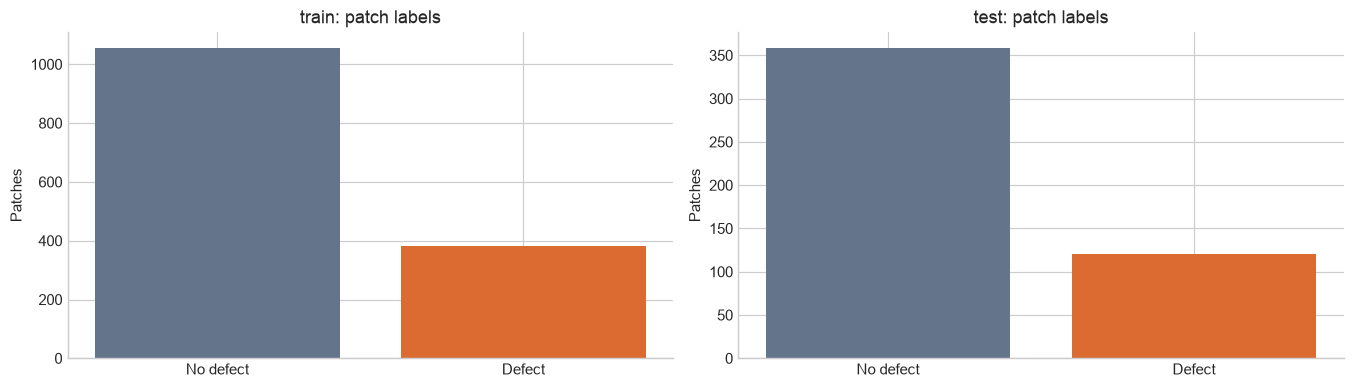

In [53]:
import sys
import torch
import ultralytics
sys.path.insert(0, str(KAGGLE_DIR))
import segmentation_compare as seg
import importlib
seg = importlib.reload(seg)

SEG_ROOT = KAGGLE_DIR / "test1_segmentation"
seg_index = seg.prepare(SEG_ROOT, DATA_DIR, manifest, labels)
seg_counts = seg_index.groupby("split").agg(
    originals=("ImageId", "nunique"), patches=("stem", "size"),
    defect_patches=("defect_pixels", lambda values: int((values > 0).sum())))
print("PyTorch", torch.__version__, "| Ultralytics", ultralytics.__version__,
      "| device", seg.DEVICE)
print(seg_counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, split in zip(axes, ["train", "test"]):
    subset = seg_index.loc[seg_index.split.eq(split)]
    ax.bar(["No defect", "Defect"],
           [(subset.defect_pixels == 0).sum(), (subset.defect_pixels > 0).sum()],
           color=[COLORS["normal"], COLORS["defect"]])
    ax.set(title=f"{split}: patch labels", ylabel="Patches")
fig.tight_layout()
plt.show()


## 17. 두 모델 학습

동일한 패치와 마스크를 사용합니다. U-Net은 회색조 1채널 입력에 `BCE + Dice` 손실과 결함 픽셀 가중치를 사용합니다. YOLO는 동일 회색조 패치를 3채널로 읽고 공식 semantic 분할 학습기를 사용합니다. 모델 크기, 사전학습, 손실 함수가 달라 결과 해석에 이 차이를 포함해야 합니다. **첫 실행은 오래 걸릴 수 있습니다.** 저장된 체크포인트가 있으면 다시 학습하지 않습니다.


In [54]:
seg.train_models(SEG_ROOT, seg_index)
print("U-Net:", SEG_ROOT / "models" / "unet_best.pt")
print("YOLO:", SEG_ROOT / "models" / "yolo" / "weights" / "best.pt")


U-Net checkpoint reused
YOLO checkpoint reused
U-Net: /Users/yoon/Documents/Codex/2026-11-03/new-chat-2/kaggle/test1_segmentation/models/unet_best.pt
YOLO: /Users/yoon/Documents/Codex/2026-11-03/new-chat-2/kaggle/test1_segmentation/models/yolo/weights/best.pt


## 18. 위치 정확도·불량 누락·처리 시간 비교

마스크 **Dice/IoU**는 예측한 붉은 픽셀과 정답 픽셀의 겹침을 측정합니다. **결함 재현율**은 결함이 있는 원본 이미지 중 예측 마스크가 한 픽셀이라도 나온 비율입니다. `FN`은 놓친 결함 이미지, `FP`는 정상 이미지에서 붉은 표시가 나온 수입니다. 한 픽셀만 예측해도 이미지 경보가 되므로 **Dice와 FP도 함께** 봐야 합니다.

U-Net의 픽셀 확률 기준은 검증 이미지에서 **이미지 재현율 95% 이상**을 만족하면서 Dice가 가장 높은 값으로 고릅니다. YOLO semantic API는 픽셀별 최종 클래스 마스크를 돌려주므로 그대로 사용합니다. 시험 세트에는 이 결정을 고정합니다. 처리 시간은 같은 Mac의 같은 장치에서, 원본 파일 읽기 → 4개 패치 → 모델 → 원본 크기 마스크 재조립까지 24장×3회 측정합니다. 처음 3장은 워밍업으로 제외합니다. 이는 200×32 RandomForest와 다른 작업입니다.

**선택 규칙은 시험 결과를 보기 전에 고정:** 검증 재현율 95%를 만족하는 후보만 선택하고, 검증 Dice 차이가 0.02 이상이면 Dice가 높은 쪽, 그렇지 않으면 지연 시간 중앙값이 낮은 쪽을 택합니다. 조건을 둘 다 못 맞추면 채택을 보류합니다.


동일한 검증/시험 원본 이미지 기준:
model  cutoff  val_dice  val_iou  val_recall  val_fn  val_fp  test_dice  test_iou  test_recall  test_fn  test_fp
 unet   0.549     0.497    0.331       1.000       0      40      0.478     0.314        0.969        2       52
 yolo   0.039     0.476    0.312       0.917       4      33      0.446     0.287        0.938        4       44
원본 1장 전체 처리 시간 (ms):
       median   mean    std
model                      
unet    36.50  46.83  43.10
yolo    44.07  53.59  31.81
선택: unet — unet만 검증 결함 재현율 95%를 충족했습니다.


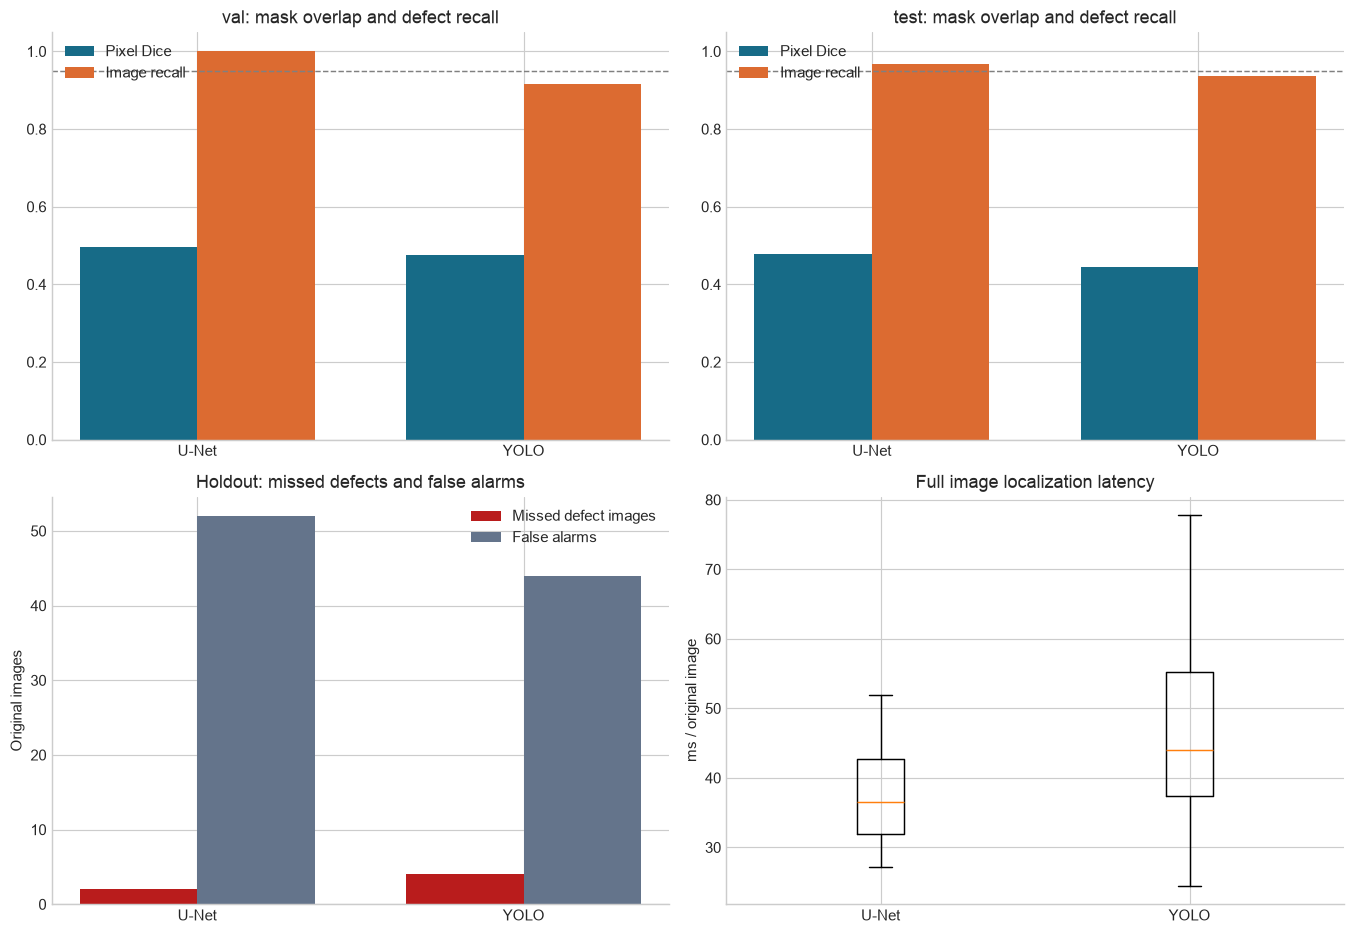

In [55]:
seg_result = seg.evaluate(SEG_ROOT, seg_index)
seg_latency = seg.benchmark(SEG_ROOT, seg_index, DATA_DIR)
seg_choice, seg_reason = seg.chosen_model(seg_result, seg_latency)
latency_table = seg_latency.groupby("model").latency_ms.agg(["median", "mean", "std"])
show_cols = ["model", "cutoff", "val_dice", "val_iou", "val_recall", "val_fn", "val_fp",
             "test_dice", "test_iou", "test_recall", "test_fn", "test_fp"]
print("동일한 검증/시험 원본 이미지 기준:")
print(seg_result[show_cols].round(3).to_string(index=False))
print("원본 1장 전체 처리 시간 (ms):")
print(latency_table.round(2).to_string())
print("선택:", seg_choice if seg_choice else "보류", "—", seg_reason)

models = ["unet", "yolo"]
colors = [COLORS["blue"], COLORS["defect"]]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for j, split in enumerate(["val", "test"]):
    metric = seg_result.set_index("model").loc[models]
    x = np.arange(2)
    axes[0, j].bar(x - .18, metric[f"{split}_dice"], .36, label="Pixel Dice", color=colors[0])
    axes[0, j].bar(x + .18, metric[f"{split}_recall"], .36, label="Image recall", color=colors[1])
    axes[0, j].axhline(.95, color="gray", linestyle="--", linewidth=1)
    axes[0, j].set(ylim=(0, 1.05), title=f"{split}: mask overlap and defect recall")
    axes[0, j].set_xticks(x, ["U-Net", "YOLO"])
    axes[0, j].legend()
axes[1, 0].bar(np.arange(2) - .18, metric.test_fn, .36, label="Missed defect images", color="#B91C1C")
axes[1, 0].bar(np.arange(2) + .18, metric.test_fp, .36, label="False alarms", color=COLORS["normal"])
axes[1, 0].set_xticks(np.arange(2), ["U-Net", "YOLO"])
axes[1, 0].set(title="Holdout: missed defects and false alarms", ylabel="Original images")
axes[1, 0].legend()
axes[1, 1].boxplot([seg_latency.loc[seg_latency.model.eq(m), "latency_ms"] for m in models],
                   tick_labels=["U-Net", "YOLO"], showfliers=False)
axes[1, 1].set(title="Full image localization latency", ylabel="ms / original image")
fig.tight_layout()
plt.show()


## 19. 실제 이미지에서 붉은 위치 비교

아래 세 행은 **홀드아웃 결함 이미지**입니다. 두 모델의 이미지별 Dice 차이가 큰 사례를 양쪽에서 골라 정답과 예측을 나란히 보여줍니다. 붉은 색은 `train.csv`에서 복원한 **정답** 또는 각 모델의 **예측 마스크**를 반투명하게 겹친 것입니다. 사례 몇 장은 설명을 돕기 위한 것이고, 우열 판단은 위 전체 표를 따릅니다. 패치를 축소했다가 원본 크기로 다시 붙이므로 경계가 계단처럼 보일 수 있습니다.


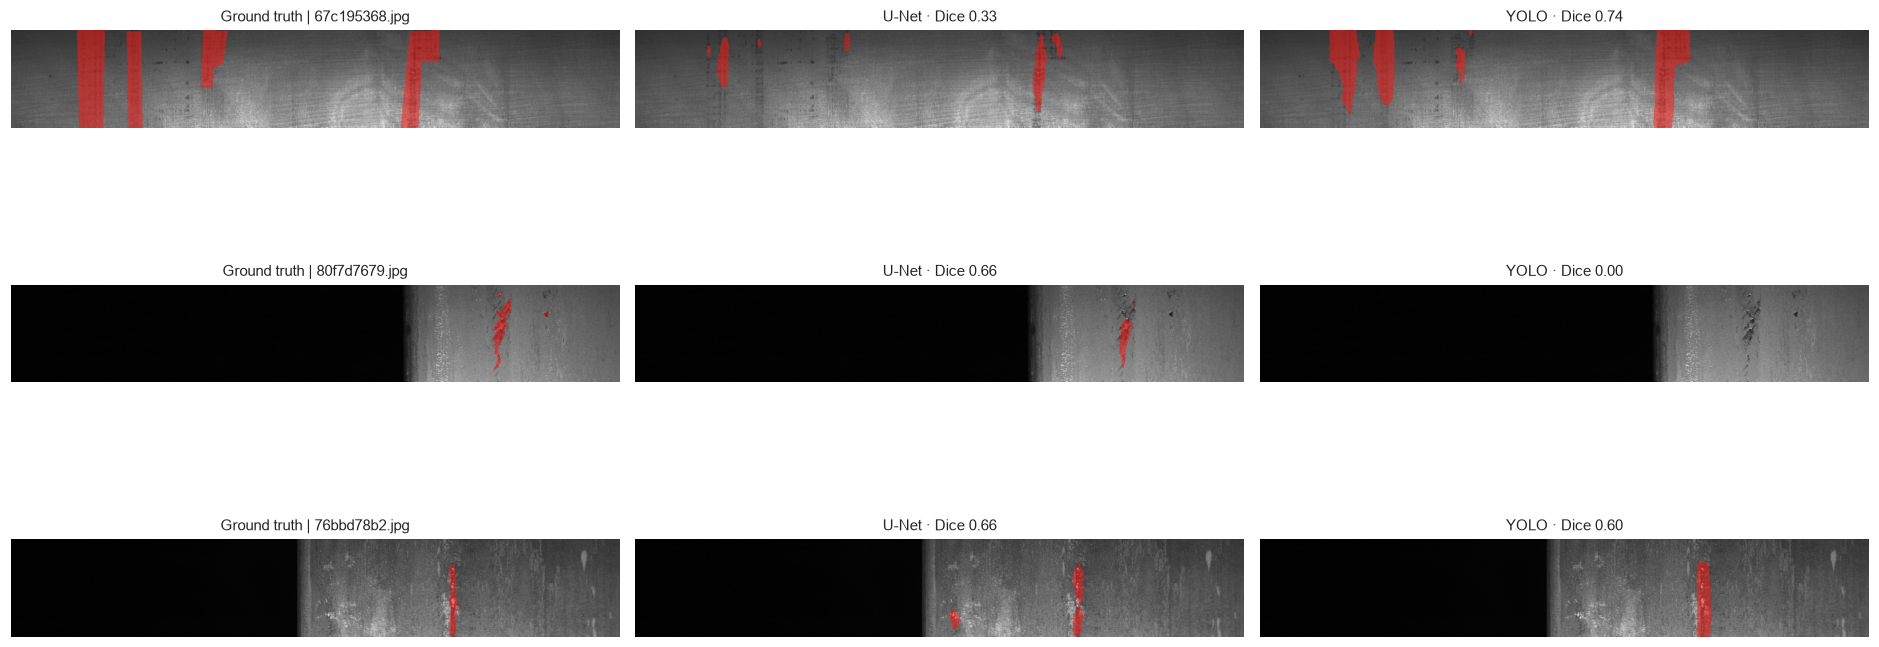

In [56]:
test_patch_rows = seg_index.loc[seg_index.split.eq("test")].reset_index(drop=True)
truth_patch = seg._truth_masks(SEG_ROOT, seg_index, "test")
image_dice = {}
for model_name in ["unet", "yolo"]:
    scores, stems = seg.predict_patch_scores(SEG_ROOT, seg_index, model_name, "test")
    assert np.array_equal(stems, test_patch_rows.stem.to_numpy())
    cutoff = float(seg_result.set_index("model").loc[model_name, "cutoff"])
    pred_patch = scores >= round(cutoff * 255)
    vals = {}
    for image_id, ids in test_patch_rows.groupby("ImageId", sort=False).indices.items():
        true = truth_patch[ids]
        pred = pred_patch[ids]
        if true.any():
            vals[image_id] = 2 * np.logical_and(true, pred).sum() / max(1, true.sum() + pred.sum())
    image_dice[model_name] = vals

diff = {image_id: image_dice["unet"][image_id] - image_dice["yolo"][image_id]
        for image_id in image_dice["unet"]}
ranked = sorted(diff, key=diff.get)
example_ids = []
for image_id in [ranked[0], ranked[-1], ranked[len(ranked)//2]]:
    if image_id not in example_ids:
        example_ids.append(image_id)
for image_id in ranked:
    if len(example_ids) == 3:
        break
    if image_id not in example_ids:
        example_ids.append(image_id)

fig, axes = plt.subplots(3, 3, figsize=(18, 8.5))
for row, image_id in enumerate(example_ids):
    with Image.open(DATA_DIR / "train_images" / image_id) as f:
        original = np.asarray(f.convert("RGB"))
    truth = np.zeros((HEIGHT, WIDTH), dtype=bool)
    for encoded in labels.loc[labels.ImageId.eq(image_id), "EncodedPixels"]:
        truth |= decode_rle(encoded)
    predicted = {m: seg.reconstruct(SEG_ROOT, seg_index, m, image_id,
                  cutoff=float(seg_result.set_index("model").loc[m, "cutoff"]))
                 for m in ["unet", "yolo"]}
    for col, (name, mask) in enumerate([("Ground truth", truth),
                                        ("U-Net", predicted["unet"]),
                                        ("YOLO", predicted["yolo"]) ]):
        overlay = np.zeros((HEIGHT, WIDTH, 4), dtype=np.float32)
        overlay[mask] = (1.0, 0.10, 0.08, 0.52)
        ax = axes[row, col]
        ax.imshow(original)
        ax.imshow(overlay)
        detail = "" if col == 0 else f" · image Dice {image_dice[name.lower()]:.2f}" if False else ""
        if col == 1:
            detail = f" · Dice {image_dice['unet'][image_id]:.2f}"
        elif col == 2:
            detail = f" · Dice {image_dice['yolo'][image_id]:.2f}"
        ax.set_title(f"{name}{detail} | {image_id}" if col == 0 else f"{name}{detail}", fontsize=10)
        ax.axis("off")
fig.tight_layout()
plt.show()


## 20. 어떤 모델을 사용할까?

위 코드의 **선택** 문구가 이번 데이터와 실행 환경에서의 임시 결론입니다. 표에서 검증 Dice와 재현율을 먼저 보고, 그래프에서 FN·FP와 원본 한 장 전체 지연 시간을 확인하세요. 아래 정답/예측 나란히 보기는 선택한 모델이 실제로 **어느 위치를 붉게 표시하는지**와 놓치는 형태를 보여줍니다. 두 모델 모두 검증 재현율 95%를 달성하지 못하면 이번 학습량으로는 채택하지 않습니다.

이 비교는 570장만 사용한 **이진 위치 표시 실험**입니다. YOLO는 외부 장면 데이터로 사전학습했고 U-Net은 초기화부터 학습한 차이가 있습니다. 픽셀별 4종 결함 분류, 여러 시점·공장 데이터, 현장 카메라 지연 시간은 아직 확인되지 않았습니다. 특히 아주 작은 결함은 320×192 패치 축소 과정에서 사라질 수 있으므로 원본 해상도 또는 더 큰 패치 입력으로 다시 비교해야 합니다.


## 21. 박스 선택과 클래스 3 위치 보정

먼저 예측 연결 영역의 **평균 점수**와 **누적 점수(픽셀 수 × 평균 점수)**를 검증 이미지에서 비교해 박스 두 개의 순위를 고릅니다. 다음으로 원래 임계값과 **약한 예측 영역의 박스 후보만 확장하는 방법**을 비교합니다. 높은 임계값을 넘는 영역이 존재하지만 그중 최대 면적이 2,000픽셀 미만이면, 박스를 찾을 때만 후보 임계값을 `60/255`로 낮춥니다. 높은 점수 영역이 전혀 없는 이미지는 확장하지 않아 새 경보를 만들지 않습니다. 검증 이미지에서 클래스 3 정답 포함률과 전체 박스 Dice가 함께 개선되고 정상 이미지 경보율이 늘지 않을 때만 확장 방식을 선택합니다.

그래프의 **박스 Dice**는 선택한 사각형과 CSV 정답 픽셀의 겹침으로, 앞의 분할 마스크 Dice와 다릅니다. 누적 점수와 후보 확장은 박스를 크게 만들 수 있으므로 정상 이미지 박스 면적도 함께 보여줍니다. 이 값들은 여러 후처리 설정을 탐색한 결과이므로 홀드아웃 수치는 최종 독립 성능 추정이 아닌 참고용입니다. 모델 학습과 앞의 분할 성능 수치는 바꾸지 않습니다.

아래 클래스 1~4의 세 칸은 **3절과 같은 파일**의 원본, CSV 마스크, 조정된 예측 박스입니다. 모델은 결함을 이진으로 예측하므로 오른쪽 박스가 가운데 특정 클래스 마스크와 일대일로 대응하지 않을 수 있습니다. 마지막에는 정답 없는 공식 시험 이미지도 표시합니다.


박스 선택 기준: sum | 검증 박스 Dice로 선택
     split rule  images  box_precision  box_coverage  box_dice  mean_box_area
validation mean      48          0.558         0.508     0.466      18642.854
validation  sum      48          0.558         0.530     0.476      21077.729
      test mean      64          0.505         0.467     0.422      16436.766
      test  sum      64          0.497         0.516     0.450      24530.344
클래스 3 박스 후보 확장: adaptive | 검증 결과로 선택
     split   policy  defect_images  class3_images  box_dice  class3_coverage  normal_false_alarm_rate  normal_box_area
validation baseline             48             38     0.476            0.582                    0.952        13137.500
validation adaptive             48             38     0.497            0.636                    0.952        16024.333
      test baseline             64             49     0.450            0.515                    0.929        16976.357
      test adaptive             64             49     0.470       

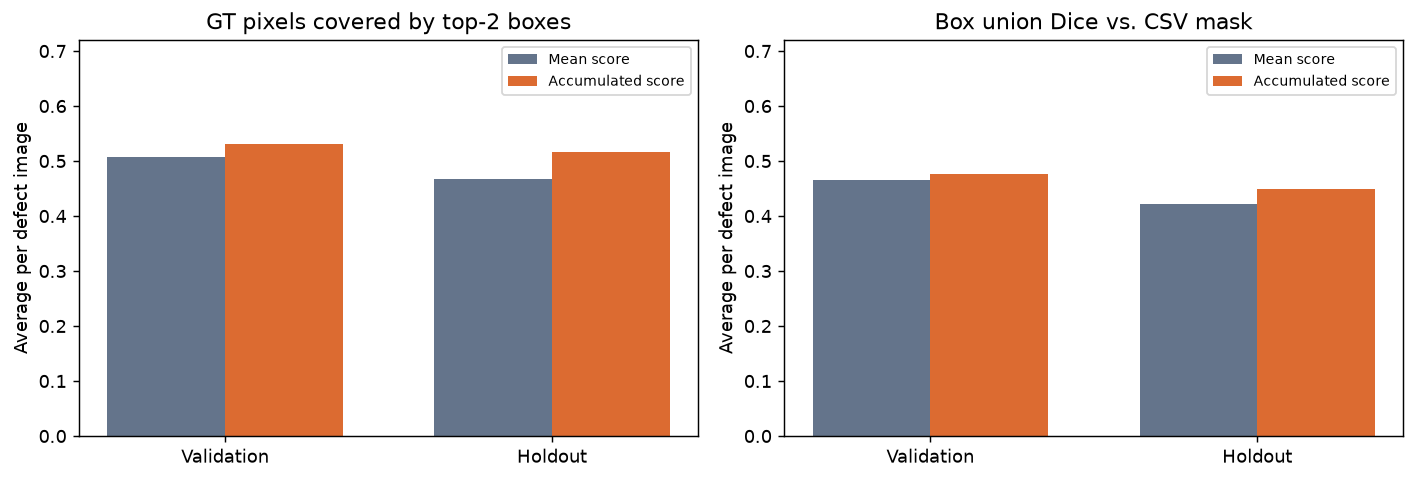

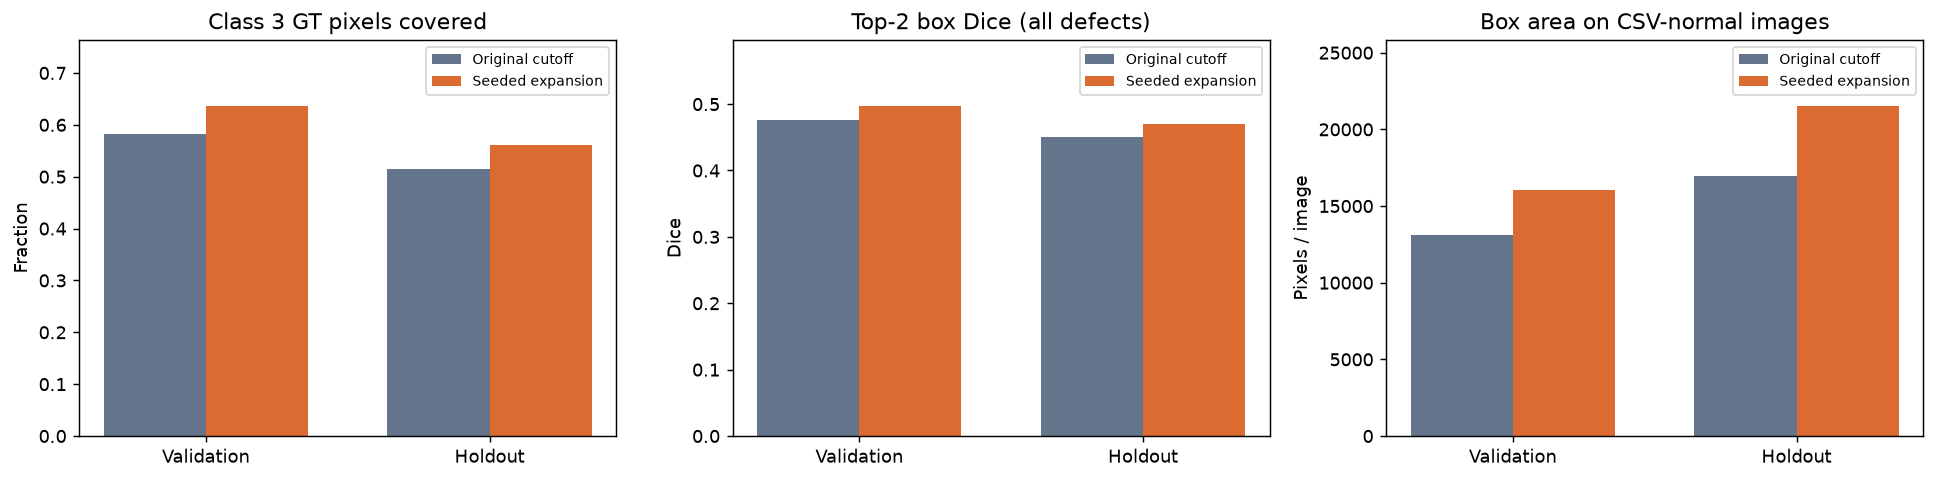

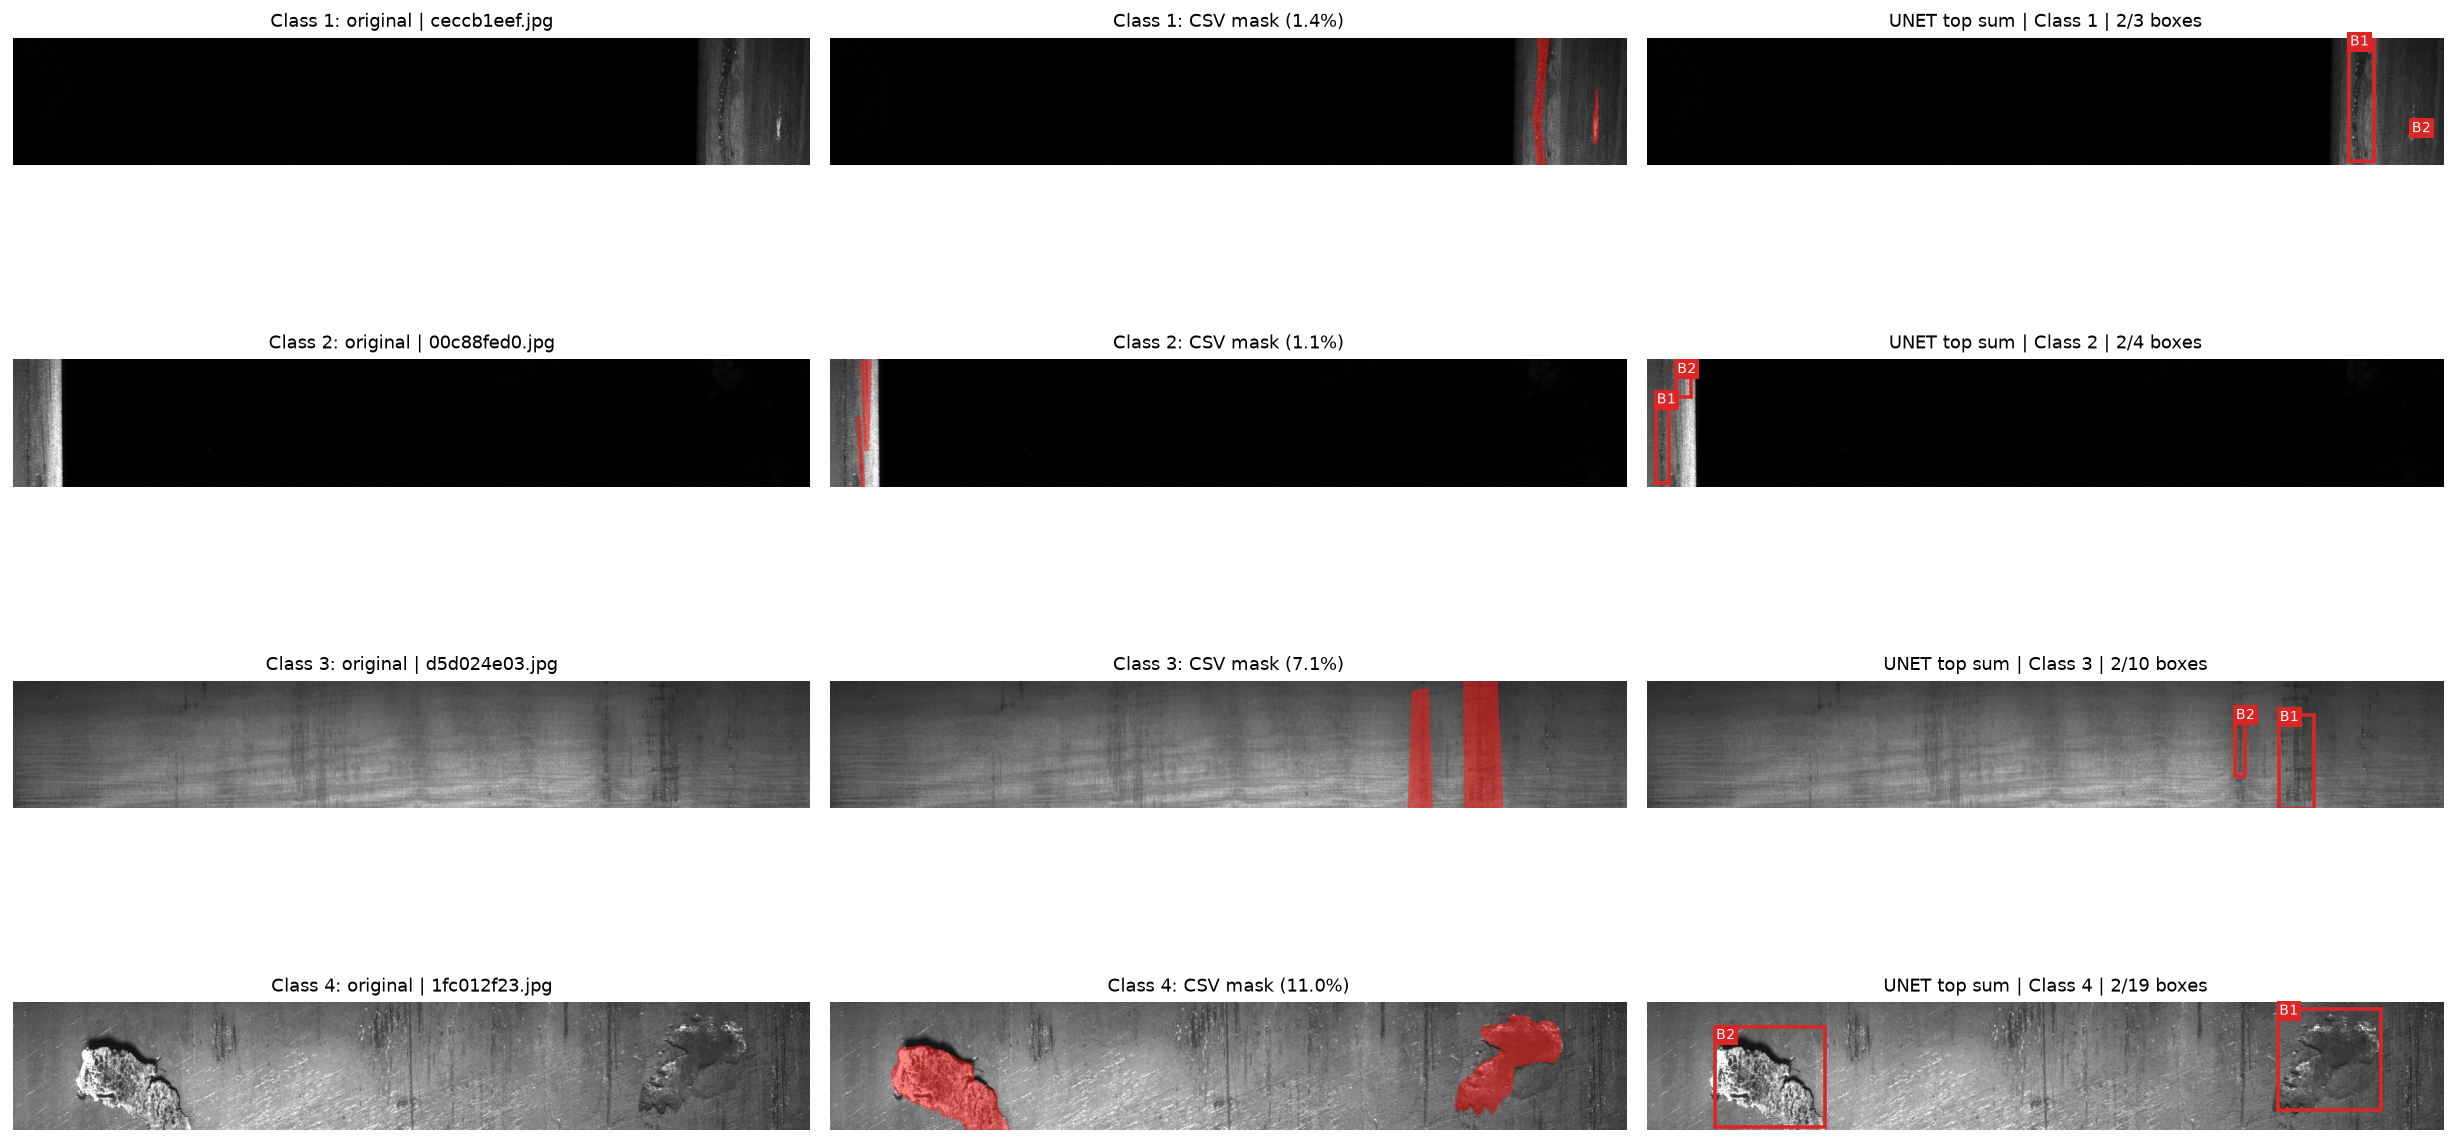

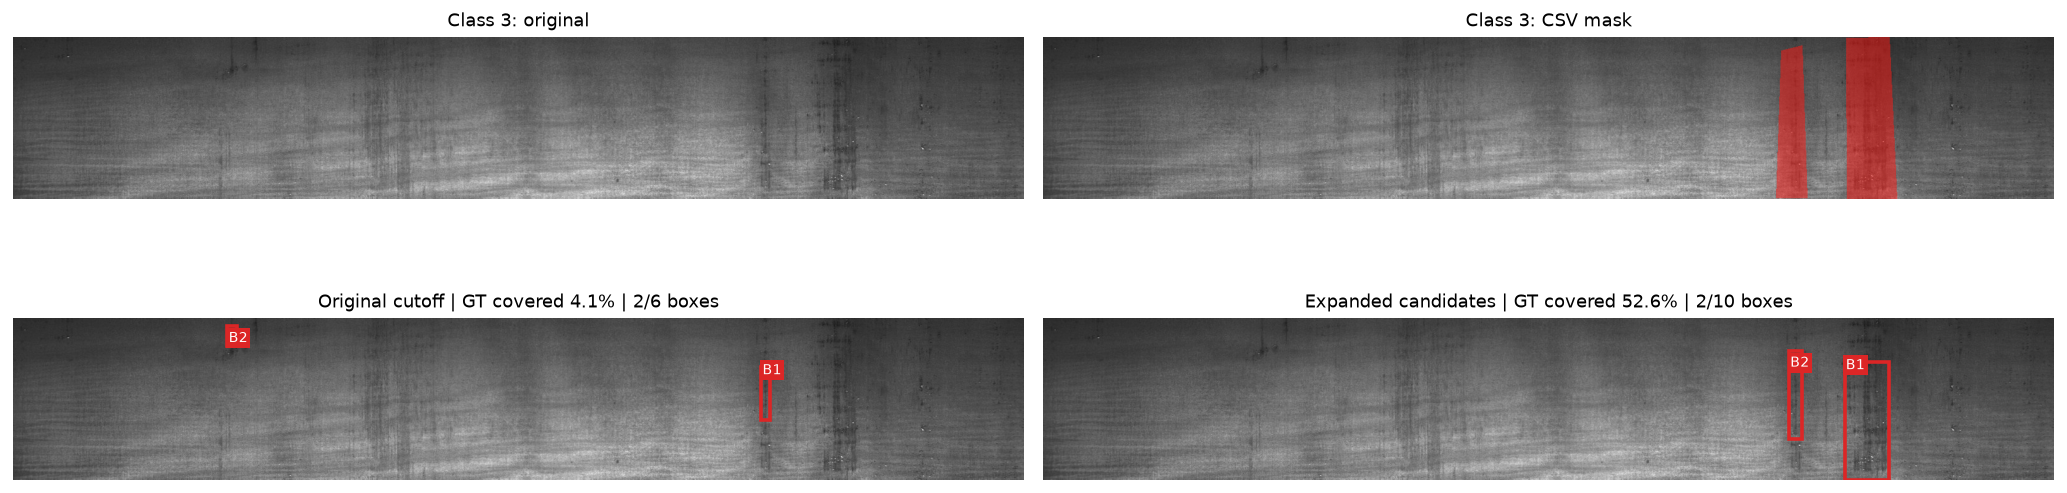

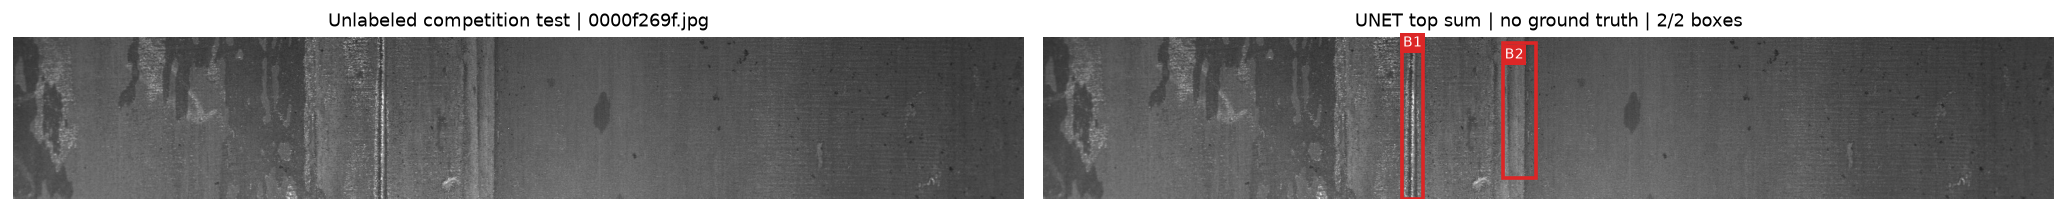

In [59]:
from matplotlib.patches import Rectangle
import importlib
import segmentation_compare as seg
seg = importlib.reload(seg)  # Jupyter 커널의 이전 모듈 정의 갱신

TOP_BOXES = 2


def mask_to_scored_boxes(mask, score_map=None, rank_rule="mean"):
    binary = np.ascontiguousarray(mask.astype(np.uint8))
    count, components, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    if score_map is not None:
        if score_map.shape != mask.shape:
            raise ValueError("점수 지도와 마스크의 크기가 다릅니다.")
        score_sums = np.bincount(components.ravel(), weights=score_map.ravel(),
                                 minlength=count)
    boxes = []
    for component in range(1, count):
        x, y, width, height, area = map(int, stats[component])
        score = (float(score_sums[component] / area / 255.0)
                 if score_map is not None else None)
        boxes.append((x, y, width, height, area, score))
    if score_map is None:
        return sorted(boxes, key=lambda box: box[4], reverse=True)
    if rank_rule == "mean":
        return sorted(boxes, key=lambda box: (box[5], box[4]), reverse=True)
    if rank_rule == "sum":
        return sorted(boxes, key=lambda box: (box[4] * box[5], box[5]), reverse=True)
    raise ValueError(f"Unknown box ranking rule: {rank_rule}")


def draw_boxes(ax, image, boxes, title, color, total=None):
    ax.imshow(image)
    for number, (x, y, width, height, area, score) in enumerate(boxes, 1):
        ax.add_patch(Rectangle((x, y), width, height,
                               fill=False, edgecolor=color, linewidth=2))
        label = f"B{number}"
        ax.text(x + 2, y + 12 + 13 * ((number - 1) % 4), label,
                color="white", fontsize=8,
                bbox={"facecolor": color, "edgecolor": "none", "pad": 1.5})
    count_label = str(len(boxes)) if total is None else f"{len(boxes)}/{total}"
    ax.set_title(f"{title} | {count_label} boxes", fontsize=10)
    ax.axis("off")


if seg_choice is None:
    print("선택된 위치 예측 모델이 없어 박스 시연을 건너뜁니다.")
else:
    cutoff = float(seg_result.set_index("model").loc[seg_choice, "cutoff"])
    cutoff_byte = round(cutoff * 255)
    box_report = seg.compare_box_selection(
        SEG_ROOT, seg_index, labels, seg_choice, cutoff, top_k=TOP_BOXES)
    validation_report = box_report.loc[box_report.split.eq("validation")]
    rank_rule = validation_report.sort_values("box_dice", ascending=False).iloc[0]["rule"]
    print("박스 선택 기준:", rank_rule, "| 검증 박스 Dice로 선택")
    print(box_report[["split", "rule", "images", "box_precision", "box_coverage",
                      "box_dice", "mean_box_area"]].round(3).to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (metric, title) in zip(
            axes, [("box_coverage", "GT pixels covered by top-2 boxes"),
                   ("box_dice", "Box union Dice vs. CSV mask")]):
        table = box_report.pivot(index="split", columns="rule", values=metric).loc[
            ["validation", "test"], ["mean", "sum"]]
        positions = np.arange(2)
        ax.bar(positions - 0.18, table["mean"], 0.36,
               label="Mean score", color="#64748B")
        ax.bar(positions + 0.18, table["sum"], 0.36,
               label="Accumulated score", color="#DC6B31")
        ax.set_xticks(positions, ["Validation", "Holdout"])
        ax.set(ylim=(0, 0.72), ylabel="Average per defect image", title=title)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    WEAK_AREA_TRIGGER = 2000
    LOW_BOX_CUTOFF = 60  # 60/255 ≈ 0.235; 원래 분할 임계값과 별개
    expansion_report = seg.compare_class3_box_expansion(
        SEG_ROOT, seg_index, labels, seg_choice, cutoff, top_k=TOP_BOXES,
        weak_area_trigger=WEAK_AREA_TRIGGER, low_cutoff_byte=LOW_BOX_CUTOFF,
        rank_rule=rank_rule)
    validation_expansion = expansion_report.set_index(["split", "policy"])
    baseline_val = validation_expansion.loc[("validation", "baseline")]
    adaptive_val = validation_expansion.loc[("validation", "adaptive")]
    use_adaptive = (adaptive_val.class3_coverage > baseline_val.class3_coverage
                    and adaptive_val.box_dice >= baseline_val.box_dice
                    and adaptive_val.normal_false_alarm_rate <= baseline_val.normal_false_alarm_rate)
    box_policy = "adaptive" if use_adaptive else "baseline"
    print("클래스 3 박스 후보 확장:", box_policy, "| 검증 결과로 선택")
    print(expansion_report[["split", "policy", "defect_images", "class3_images",
                            "box_dice", "class3_coverage", "normal_false_alarm_rate",
                            "normal_box_area"]].round(3).to_string(index=False))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (metric, title, unit) in zip(
            axes, [("class3_coverage", "Class 3 GT pixels covered", "Fraction"),
                   ("box_dice", "Top-2 box Dice (all defects)", "Dice"),
                   ("normal_box_area", "Box area on CSV-normal images", "Pixels / image")]):
        table = expansion_report.pivot(index="split", columns="policy", values=metric).loc[
            ["validation", "test"], ["baseline", "adaptive"]]
        positions = np.arange(2)
        ax.bar(positions - 0.18, table["baseline"], 0.36,
               label="Original cutoff", color="#64748B")
        ax.bar(positions + 0.18, table["adaptive"], 0.36,
               label="Seeded expansion", color="#DC6B31")
        ax.set_xticks(positions, ["Validation", "Holdout"])
        ax.set(ylim=(0, max(table.max()) * 1.2), ylabel=unit, title=title)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    reference_rows = []
    class3_comparison = None
    for class_id in range(1, 5):
        group = labels.loc[labels.ClassId.eq(class_id)]
        target = group.area_px.quantile(0.75)
        reference_rows.append(group.loc[(group.area_px - target).abs().idxmin()])

    fig, axes = plt.subplots(4, 3, figsize=(19, 11))
    for row_number, record in enumerate(reference_rows):
        image_path = DATA_DIR / "train_images" / record.ImageId
        with Image.open(image_path) as image_file:
            image = np.asarray(image_file.convert("RGB"))
        truth_mask = decode_rle(record.EncodedPixels)
        score_map = seg.predict_original_scores(SEG_ROOT, image_path, seg_choice)
        candidate_mask, used_cutoff, high_seed_area = seg.box_candidate_mask(
            score_map, cutoff_byte, WEAK_AREA_TRIGGER, LOW_BOX_CUTOFF,
            adaptive=(box_policy == "adaptive"))
        candidate_boxes = mask_to_scored_boxes(candidate_mask, score_map, rank_rule)
        top_boxes = candidate_boxes[:TOP_BOXES]

        axes[row_number, 0].imshow(image)
        axes[row_number, 0].set_title(f"Class {record.ClassId}: original | {record.ImageId}", fontsize=10)
        axes[row_number, 0].axis("off")

        overlay = np.zeros((HEIGHT, WIDTH, 4), dtype=np.float32)
        overlay[truth_mask] = (1.0, 0.10, 0.08, 0.52)
        axes[row_number, 1].imshow(image)
        axes[row_number, 1].imshow(overlay)
        axes[row_number, 1].set_title(
            f"Class {record.ClassId}: CSV mask ({100 * truth_mask.mean():.1f}%)", fontsize=10)
        axes[row_number, 1].axis("off")

        draw_boxes(axes[row_number, 2], image, top_boxes,
                   f"{seg_choice.upper()} top {rank_rule} | Class {record.ClassId}", "#DC2626",
                   total=len(candidate_boxes))
        sampled = seg_index.loc[seg_index.ImageId.eq(record.ImageId), "split"].unique()
        sample_status = sampled[0] if len(sampled) else "outside 570-image experiment"
        box_union = np.zeros_like(truth_mask)
        for x, y, width, height, _, _ in top_boxes:
            box_union[y:y + height, x:x + width] = True
        example_coverage = np.logical_and(truth_mask, box_union).sum() / max(1, truth_mask.sum())
        print(f"Class {record.ClassId} | {record.ImageId} | {sample_status}"
              f" | candidates {len(candidate_boxes)} -> shown {len(top_boxes)}"
              f" | candidate cutoff {used_cutoff}/255 | selected CSV-mask coverage {example_coverage:.1%}"
              f" | mean scores {[round(box[5], 3) for box in top_boxes]}")
        if int(record.ClassId) == 3:
            class3_comparison = (image.copy(), truth_mask.copy(), score_map.copy())
    fig.tight_layout()
    plt.show()

    # 같은 클래스 3 사진에서 조정 전후의 박스 위치를 직접 비교합니다.
    class3_image, class3_truth, class3_scores = class3_comparison
    fig, axes = plt.subplots(2, 2, figsize=(16, 5.2))
    axes[0, 0].imshow(class3_image)
    axes[0, 0].set_title("Class 3: original", fontsize=10)
    axes[0, 0].axis("off")
    truth_overlay = np.zeros((HEIGHT, WIDTH, 4), dtype=np.float32)
    truth_overlay[class3_truth] = (1.0, 0.10, 0.08, 0.52)
    axes[0, 1].imshow(class3_image)
    axes[0, 1].imshow(truth_overlay)
    axes[0, 1].set_title("Class 3: CSV mask", fontsize=10)
    axes[0, 1].axis("off")
    for ax, adaptive in ((axes[1, 0], False), (axes[1, 1], True)):
        comparison_mask, comparison_cutoff, _ = seg.box_candidate_mask(
            class3_scores, cutoff_byte, WEAK_AREA_TRIGGER, LOW_BOX_CUTOFF,
            adaptive=adaptive)
        comparison_candidates = mask_to_scored_boxes(
            comparison_mask, class3_scores, rank_rule)
        comparison_boxes = comparison_candidates[:TOP_BOXES]
        comparison_union = np.zeros_like(class3_truth)
        for x, y, width, height, _, _ in comparison_boxes:
            comparison_union[y:y + height, x:x + width] = True
        comparison_coverage = np.logical_and(class3_truth, comparison_union).sum() / max(1, class3_truth.sum())
        title = ("Expanded candidates" if adaptive else "Original cutoff")
        draw_boxes(ax, class3_image, comparison_boxes,
                   f"{title} | GT covered {comparison_coverage:.1%}", "#DC2626",
                   total=len(comparison_candidates))
    fig.tight_layout()
    plt.show()

    unseen_path = test_paths[0]
    unseen_scores = seg.predict_original_scores(SEG_ROOT, unseen_path, seg_choice)
    with Image.open(unseen_path) as image_file:
        unseen_image = np.asarray(image_file.convert("RGB"))
    unseen_mask, unseen_cutoff, _ = seg.box_candidate_mask(
        unseen_scores, cutoff_byte, WEAK_AREA_TRIGGER, LOW_BOX_CUTOFF,
        adaptive=(box_policy == "adaptive"))
    unseen_candidates = mask_to_scored_boxes(unseen_mask, unseen_scores, rank_rule)
    unseen_boxes = unseen_candidates[:TOP_BOXES]
    fig, axes = plt.subplots(1, 2, figsize=(16, 2.8))
    axes[0].imshow(unseen_image)
    axes[0].set_title(f"Unlabeled competition test | {unseen_path.name}", fontsize=10)
    axes[0].axis("off")
    draw_boxes(axes[1], unseen_image, unseen_boxes,
               f"{seg_choice.upper()} top {rank_rule} | no ground truth", "#DC2626",
               total=len(unseen_candidates))
    fig.tight_layout()
    plt.show()
    print(f"Official test | {unseen_path.name} | candidates {len(unseen_candidates)}"
          f" -> shown {len(unseen_boxes)} | candidate cutoff {unseen_cutoff}/255"
          f" | scores {[round(box[5], 3) for box in unseen_boxes]}")


### 이번 박스 조정의 해석

저장된 실행 결과에서 클래스 3 정답 픽셀의 박스 포함률은 검증 이미지 **58.2% → 63.6%**, 홀드아웃 이미지 **51.5% → 56.1%**였습니다. 위에 나란히 표시한 같은 클래스 3 사진은 **4.1% → 52.6%**입니다. 이는 사각형이 정답을 얼마나 덮는지 나타내며, 모델의 분할 정확도나 결함 확률은 아닙니다.

정상 이미지의 박스 생성 비율은 변하지 않았지만 검증에서 **95.2%**로 높고, 박스 면적은 커졌습니다. 따라서 이 박스는 위치 설명용이며 실제 자동 판정에는 그대로 쓰기 어렵습니다. 클래스 3을 더 정확히 찾으려면 해당 결함을 더 많이 포함해 분할 모델을 다시 학습하고 정상 이미지 오경보도 함께 낮춰야 합니다.


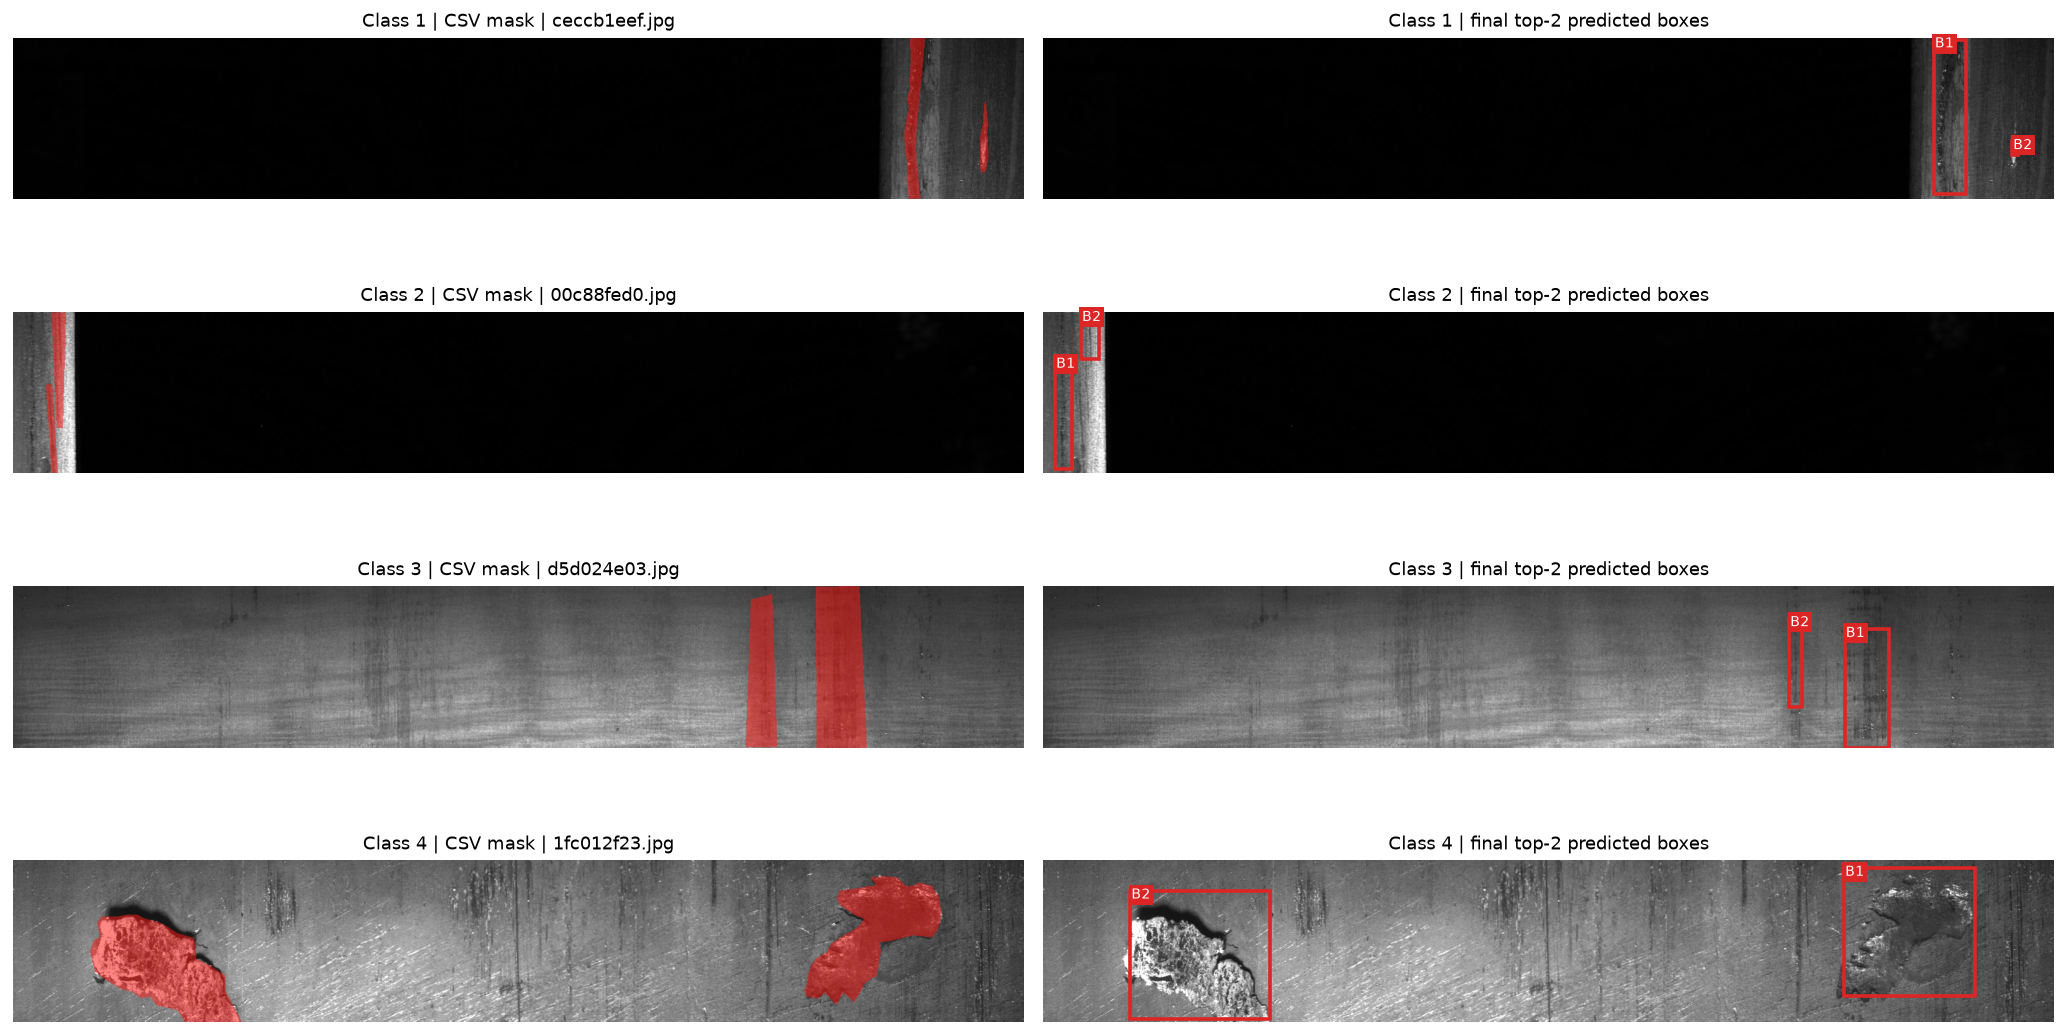

In [60]:
# 21절 실행 뒤: 같은 사진의 원래 CSV 마킹과 최종 예측 박스 2개만 비교
fig, axes = plt.subplots(4, 2, figsize=(16, 9))
for row_number, record in enumerate(reference_rows):
    image_path = DATA_DIR / "train_images" / record.ImageId
    with Image.open(image_path) as image_file:
        image = np.asarray(image_file.convert("RGB"))
    truth_mask = decode_rle(record.EncodedPixels)

    # 왼쪽: 처음 사용한 CSV 정답 마스크의 붉은 표시
    overlay = np.zeros((HEIGHT, WIDTH, 4), dtype=np.float32)
    overlay[truth_mask] = (1.0, 0.10, 0.08, 0.52)
    axes[row_number, 0].imshow(image)
    axes[row_number, 0].imshow(overlay)
    axes[row_number, 0].set_title(
        f"Class {int(record.ClassId)} | CSV mask | {record.ImageId}", fontsize=10)
    axes[row_number, 0].axis("off")

    # 오른쪽: 선택된 모델의 같은 사진 예측에서 상위 2개 박스만 표시
    scores = seg.predict_original_scores(SEG_ROOT, image_path, seg_choice)
    candidate_mask, _, _ = seg.box_candidate_mask(
        scores, cutoff_byte, WEAK_AREA_TRIGGER, LOW_BOX_CUTOFF,
        adaptive=(box_policy == "adaptive"))
    final_boxes = mask_to_scored_boxes(candidate_mask, scores, rank_rule)[:2]
    axes[row_number, 1].imshow(image)
    for box_number, (x, y, width, height, _, _) in enumerate(final_boxes, 1):
        axes[row_number, 1].add_patch(Rectangle(
            (x, y), width, height, fill=False, edgecolor="#DC2626", linewidth=2))
        axes[row_number, 1].text(
            x + 2, y + 12, f"B{box_number}", color="white", fontsize=8,
            bbox={"facecolor": "#DC2626", "edgecolor": "none", "pad": 1.5})
    axes[row_number, 1].set_title(
        f"Class {int(record.ClassId)} | final top-2 predicted boxes", fontsize=10)
    axes[row_number, 1].axis("off")
fig.tight_layout()
plt.show()
